In [ ]:
pip install numpy pandas matplotlib scikit-learn scipy shap joblib openpyxl


Training High-Capacity LightGBM Model...
Training Completed.

LIGHTGBM HIGH-PERFORMANCE METRICS
Train R²  : 0.8212
Test R²   : 0.8092
Train RMSE: 0.1140
Test RMSE : 0.1179
Train MAE : 0.0836
Test MAE  : 0.0861


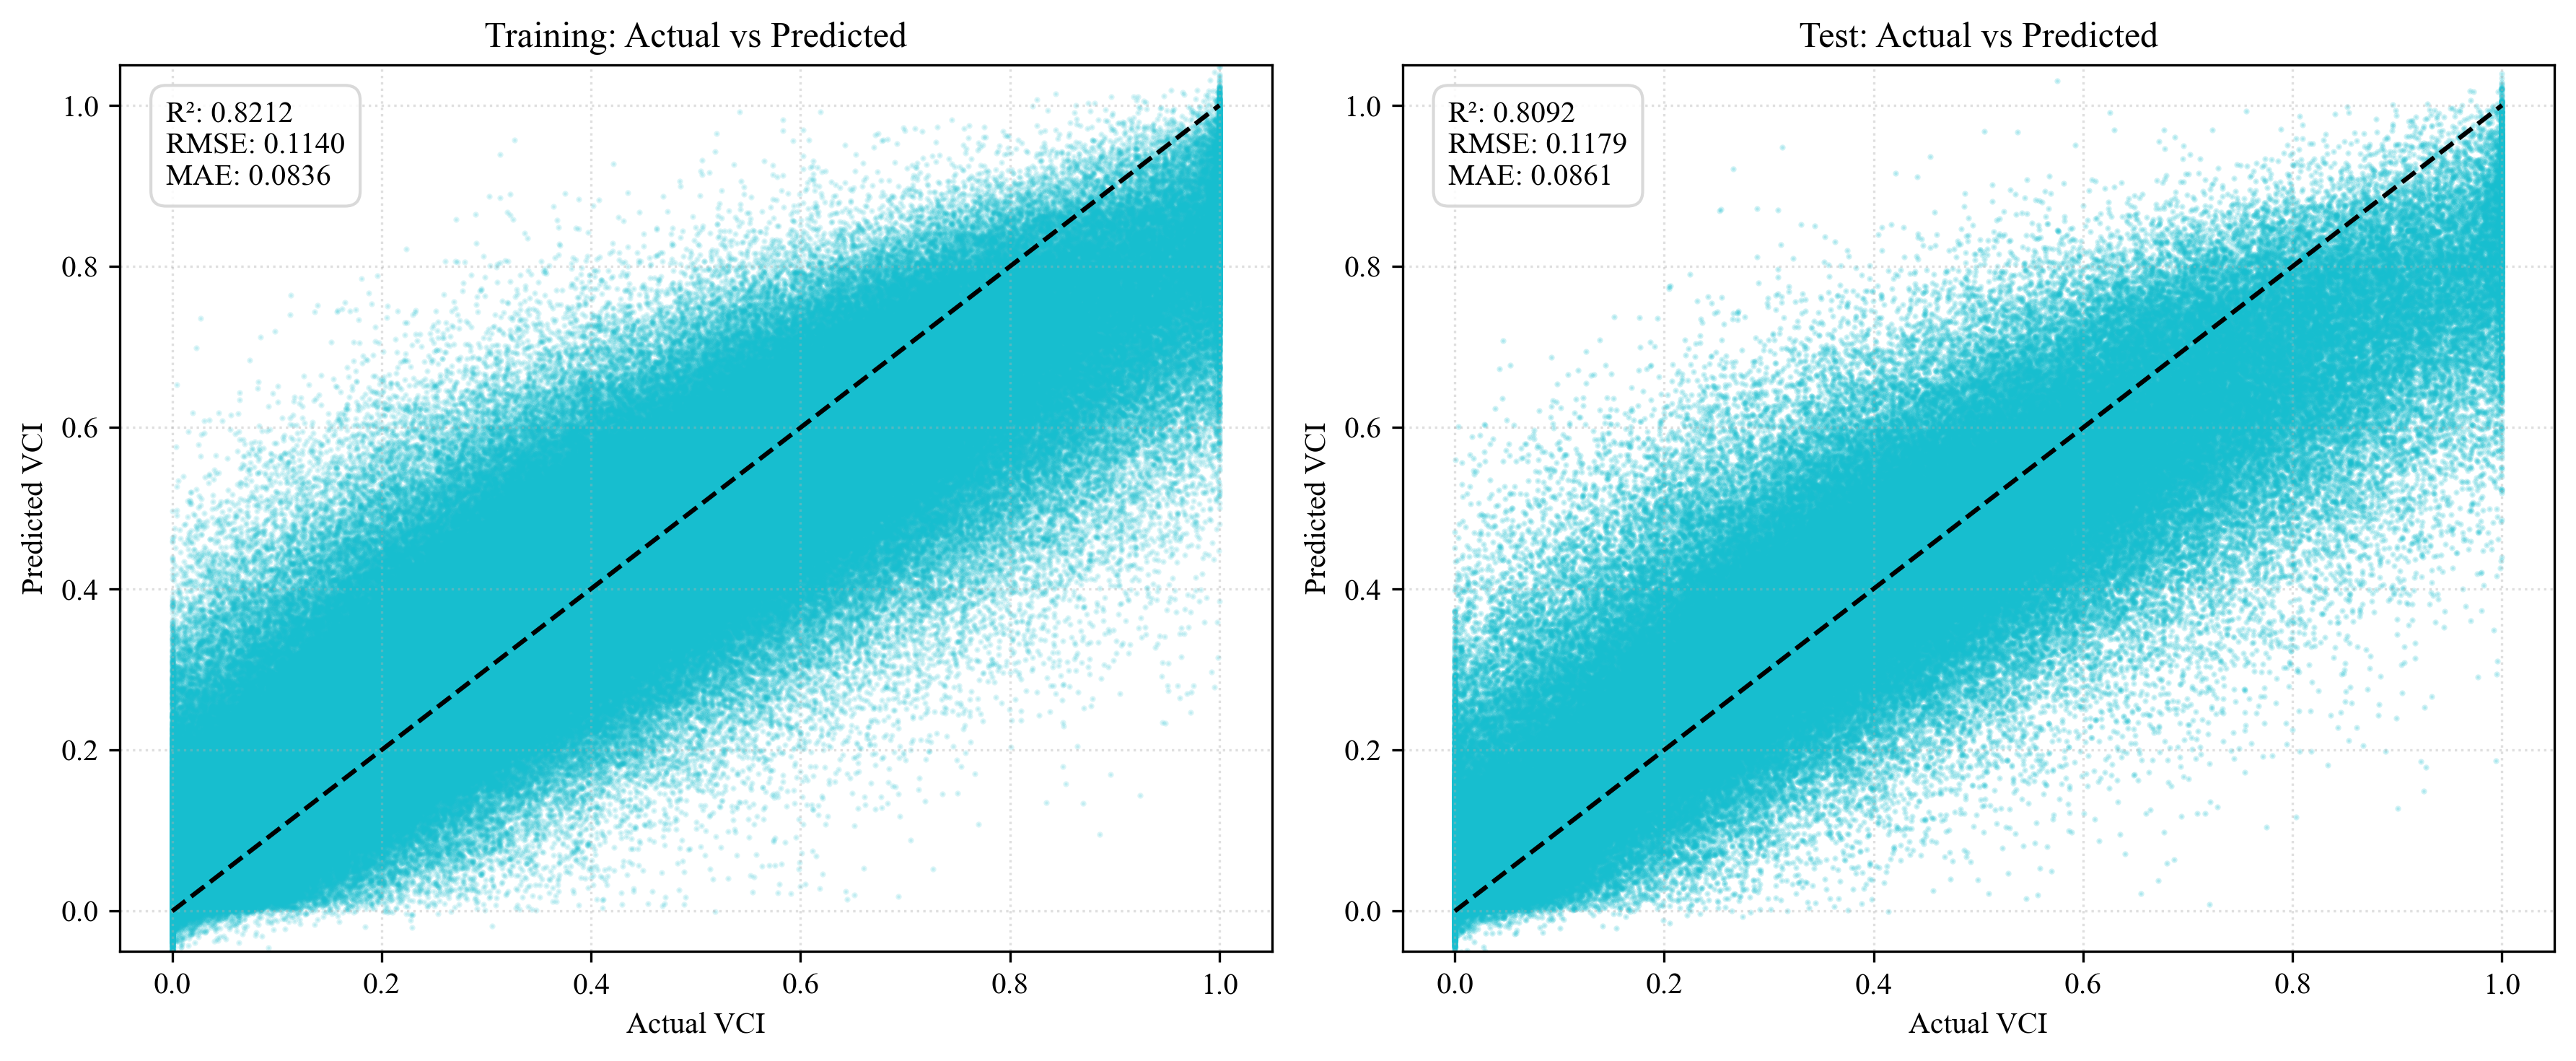

In [24]:
# ======================================================================
# LightGBM - High-Capacity Tuning for Max R²
# ======================================================================
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from lightgbm import LGBMRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Input Path from your setup
ml_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output"
input_csv = os.path.join(ml_dir, "lagged_ml_ready.csv")

# Data Loading
df = pd.read_csv(input_csv)
drop_columns = ["VCI", "Row_Idx", "Col_Idx", "Year"]
X = df.drop(columns=drop_columns)
y = df["VCI"].copy()

target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

# ======================================================================
# HIGH-PERFORMANCE / ENHANCED CAPACITY LIGHTGBM PARAMETERS
# ======================================================================
print("\nTraining High-Capacity LightGBM Model...")
lgbm_model = LGBMRegressor(
    n_estimators=400,          # Increased trees to capture complex lag relationships
    learning_rate=0.05,        # Smaller step size for better convergence with high tree count
    max_depth=10,               # Deeper tree hierarchy allowed
    num_leaves=128,             # Significantly increased complexity (main driver for LightGBM)
    min_child_samples=10,       # Lower value allows leaves to isolate finer local patterns
    subsample=0.85,             # Row subsampling
    subsample_freq=1,           
    colsample_bytree=0.85,      # Feature subsampling
    reg_alpha=0.05,             # Minimal L1 regularization
    reg_lambda=0.5,             # Mild L2 regularization
    random_state=RANDOM_STATE,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)
print("Training Completed.")

# Performance Predictions
train_pred = lgbm_model.predict(X_train)
test_pred = lgbm_model.predict(X_test)

# Metrics Calculation
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
train_mae = mean_absolute_error(y_train, train_pred)
test_mae = mean_absolute_error(y_test, test_pred)

print("\n" + "="*75)
print("LIGHTGBM HIGH-PERFORMANCE METRICS")
print("="*75)
print(f"Train R²  : {train_r2:.4f}")
print(f"Test R²   : {test_r2:.4f}")
print(f"Train RMSE: {train_rmse:.4f}")
print(f"Test RMSE : {test_rmse:.4f}")
print(f"Train MAE : {train_mae:.4f}")
print(f"Test MAE  : {test_mae:.4f}")
print("="*75)

# Journal Style Visualization
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300
fig = plt.figure(figsize=(12, 5), facecolor='white')
box_props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='lightgray')

# Training Plot
ax1 = plt.subplot(1, 2, 1, facecolor='white')
plt.scatter(y_train, train_pred, alpha=0.15, color='tab:cyan', s=1)
plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
train_text = f"R²: {train_r2:.4f}\nRMSE: {train_rmse:.4f}\nMAE: {train_mae:.4f}"
ax1.text(0.04, 0.96, train_text, transform=ax1.transAxes, fontsize=10, bbox=box_props, verticalalignment='top', horizontalalignment='left')
plt.xlim([-0.05, 1.05]); plt.ylim([-0.05, 1.05])
plt.xlabel('Actual VCI')
plt.ylabel('Predicted VCI')
plt.title('Training: Actual vs Predicted')
plt.grid(True, linestyle=':', alpha=0.4)

# Testing Plot
ax2 = plt.subplot(1, 2, 2, facecolor='white')
plt.scatter(y_test, test_pred, alpha=0.2, color='tab:cyan', s=1)
plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
test_text = f"R²: {test_r2:.4f}\nRMSE: {test_rmse:.4f}\nMAE: {test_mae:.4f}"
ax2.text(0.04, 0.96, test_text, transform=ax2.transAxes, fontsize=10, bbox=box_props, verticalalignment='top', horizontalalignment='left')
plt.xlim([-0.05, 1.05]); plt.ylim([-0.05, 1.05])
plt.xlabel('Actual VCI')
plt.ylabel('Predicted VCI')
plt.title('Test: Actual vs Predicted')
plt.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

In [28]:
# ======================================================================
# COMBINED BENCHMARKING PIPELINE: XGBoost, LightGBM, Random Forest
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# STEP 1: GLOBAL CONFIGURATION & OUTPUT DIRECTORY
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Output directory for saving all plots and results
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output"
os.makedirs(output_dir, exist_ok=True)

print("\nReading Dataset...")

# ======================================================================
# STEP 2: DATA LOADING, NORMALIZATION & 70/30 SPLIT
# ======================================================================
print("\nReading Dataset...")

# Change this path to match where 'lagged_ml_ready.csv' actually lives:
ml_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output"

input_csv = os.path.join(ml_dir, "lagged_ml_ready.csv")

# Verify if file exists before reading
if not os.path.exists(input_csv):
    raise FileNotFoundError(
        f"Could not find the file at: {input_csv}\n"
        "Please double-check the folder path and file name on your E: drive!"
    )

df = pd.read_csv(input_csv)
print(f"Dataset Shape: {df.shape}")

# Global Matplotlib settings for publication quality
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

print("=" * 70)
print(f"OUTPUT FOLDER READY: {output_dir}")
print("=" * 70)

# ======================================================================
# STEP 2: DATA LOADING, NORMALIZATION & 70/30 SPLIT
# ======================================================================
print("\nReading Dataset...")
df = pd.read_csv(input_csv)
print(f"Dataset Shape: {df.shape}")

drop_columns = ["VCI", "Row_Idx", "Col_Idx", "Year"]
X = df.drop(columns=drop_columns)
y = df["VCI"].copy()

# Target Normalization [0, 1]
target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

# Reproducible 70/30 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

print(f"Training Samples : {len(X_train)}")
print(f"Testing Samples  : {len(X_test)}")

# Container for storing evaluation metrics and predictions
model_results = {}

# ======================================================================
# STEP 3: DEFINE MODELS WITH EXACT HYPERPARAMETERS
# ======================================================================
models = {
    "XGBoost": XGBRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=15,
        min_child_weight=7,
        subsample=0.75,
        colsample_bytree=0.75,
        gamma=0.01,
        reg_alpha=0.8,
        reg_lambda=2.0,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
        eval_metric="rmse"
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=10,
        num_leaves=128,
        min_child_samples=10,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=0.5,
        random_state=RANDOM_STATE,
        verbosity=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=600,
        max_depth=15,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features="sqrt",
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# ======================================================================
# STEP 4: MODEL TRAINING & EVALUATION
# ======================================================================
print("\n" + "=" * 70)
print("STARTING TRAINING & EVALUATION")
print("=" * 70)

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)
    
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    
    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)
    
    # Save predictions and metrics
    model_results[name] = {
        "train_pred": train_pred,
        "test_pred": test_pred,
        "train_r2": train_r2,
        "test_r2": test_r2,
        "train_rmse": train_rmse,
        "test_rmse": test_rmse,
        "train_mae": train_mae,
        "test_mae": test_mae,
        "train_res": y_train - train_pred,
        "test_res": y_test - test_pred
    }
    
    print(f"[{name}] Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f}")
    print(f"[{name}] Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f}")

# ======================================================================
# STEP 5: INDIVIDUAL SCATTER PLOTS (Cyan Style for All 3 Models)
# ======================================================================
box_props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='lightgray')

for name, res in model_results.items():
    fig = plt.figure(figsize=(12, 5), facecolor='white')
    
    # --- Training Plot ---
    ax1 = plt.subplot(1, 2, 1, facecolor='white')
    plt.scatter(y_train, res['train_pred'], alpha=0.15, color='tab:cyan', s=1)
    plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
    train_text = f"R²: {res['train_r2']:.4f}\nRMSE: {res['train_rmse']:.4f}\nMAE: {res['train_mae']:.4f}"
    ax1.text(0.04, 0.96, train_text, transform=ax1.transAxes, fontsize=10, 
             bbox=box_props, verticalalignment='top', horizontalalignment='left')
    plt.xlim([-0.05, 1.05]); plt.ylim([-0.05, 1.05])
    plt.xlabel('Actual VCI')
    plt.ylabel('Predicted VCI')
    plt.title(f'{name} - Training: Actual vs Predicted')
    plt.grid(True, linestyle=':', alpha=0.4)

    # --- Testing Plot ---
    ax2 = plt.subplot(1, 2, 2, facecolor='white')
    plt.scatter(y_test, res['test_pred'], alpha=0.2, color='tab:cyan', s=1)
    plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
    test_text = f"R²: {res['test_r2']:.4f}\nRMSE: {res['test_rmse']:.4f}\nMAE: {res['test_mae']:.4f}"
    ax2.text(0.04, 0.96, test_text, transform=ax2.transAxes, fontsize=10, 
             bbox=box_props, verticalalignment='top', horizontalalignment='left')
    plt.xlim([-0.05, 1.05]); plt.ylim([-0.05, 1.05])
    plt.xlabel('Actual VCI')
    plt.ylabel('Predicted VCI')
    plt.title(f'{name} - Test: Actual vs Predicted')
    plt.grid(True, linestyle=':', alpha=0.4)

    plt.tight_layout()
    plot_file = os.path.join(output_dir, f"{name.replace(' ', '_')}_Scatterplot.png")
    plt.savefig(plot_file, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"Saved Scatterplot: {plot_file}")

# ======================================================================
# STEP 6: SEPARATE & COMPARATIVE BOXPLOTS
# ======================================================================

# 1. Individual Boxplots for each model (Train vs Test Absolute Errors)
for name, res in model_results.items():
    fig, ax = plt.subplots(figsize=(6, 5), facecolor='white')
    
    abs_err_train = np.abs(res['train_res'])
    abs_err_test = np.abs(res['test_res'])
    
    box = ax.boxplot([abs_err_train, abs_err_test], labels=['Train Error', 'Test Error'],
                     patch_artist=True, showfliers=False,
                     boxprops=dict(facecolor='cyan', alpha=0.5, color='darkcyan'),
                     medianprops=dict(color='black', linewidth=1.5))
    
    ax.set_title(f"{name} - Absolute Residual Error Distribution", fontsize=11)
    ax.set_ylabel("Absolute Error (|Actual - Predicted|)")
    ax.grid(True, linestyle=":", alpha=0.4)
    
    plt.tight_layout()
    box_file = os.path.join(output_dir, f"{name.replace(' ', '_')}_Boxplot.png")
    plt.savefig(box_file, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"Saved Individual Boxplot: {box_file}")

# 2. Combined Comparative Boxplot Across All 3 Models (Test Errors)
fig, ax = plt.subplots(figsize=(8, 5), facecolor='white')
all_test_errors = [np.abs(model_results[m]['test_res']) for m in models.keys()]

bp = ax.boxplot(all_test_errors, labels=list(models.keys()), patch_artist=True,
                showfliers=False, medianprops=dict(color='black', linewidth=1.5))

colors = ['cyan', 'skyblue', 'teal']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax.set_title("Test Set Absolute Residual Error Comparison Across All Models", fontsize=11)
ax.set_ylabel("Absolute Residual Error")
ax.grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()
comp_box_file = os.path.join(output_dir, "All_Models_Boxplot_Comparison.png")
plt.savefig(comp_box_file, dpi=300, bbox_inches='tight')
plt.close()
print(f"Saved Comparative Boxplot: {comp_box_file}")

# ======================================================================
# STEP 7: TAYLOR DIAGRAM (All 3 Models in One Image)
# ======================================================================
fig = plt.figure(figsize=(7, 7), facecolor='white')
ax = fig.add_subplot(111, polar=True)

# Restrict angle to first quadrant (Correlation 0.0 to 1.0)
ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

# Correlation arc grid
corr_ticks = np.array([0.0, 0.2, 0.4, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98, 1.0])
angles = np.arccos(corr_ticks)
ax.set_thetagrids(np.degrees(angles), labels=[str(c) for c in corr_ticks])

# Reference Standard Deviation (Observed Test Data)
std_ref = np.std(y_test)
ax.plot(0, std_ref, 'ko', markersize=9, label='Observed (Reference)')

# Model markers & colors
model_styles = {
    "XGBoost": {"marker": "s", "color": "darkcyan"},
    "LightGBM": {"marker": "^", "color": "blue"},
    "Random Forest": {"marker": "o", "color": "purple"}
}

for name, res in model_results.items():
    std_pred = np.std(res['test_pred'])
    corr = np.corrcoef(y_test, res['test_pred'])[0, 1]
    theta = np.arccos(corr)
    
    style = model_styles[name]
    ax.plot(theta, std_pred, marker=style["marker"], color=style["color"],
            markersize=9, linestyle='None', label=f"{name} (R={corr:.4f})")

ax.set_title("Taylor Diagram - Model Performance Comparison", pad=25, fontsize=12, fontweight='bold')
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.15))
plt.tight_layout()

taylor_file = os.path.join(output_dir, "Taylor_Diagram_Comparison.png")
plt.savefig(taylor_file, dpi=300, bbox_inches='tight')
plt.close()
print(f"Saved Taylor Diagram: {taylor_file}")

# ======================================================================
# STEP 8: GRADIENT / RESIDUAL ERROR DISTRIBUTION PLOT
# ======================================================================
fig, ax = plt.subplots(figsize=(10, 5), facecolor='white')

for name, res in model_results.items():
    residuals = res['test_res']
    kde = stats.gaussian_kde(residuals)
    x_range = np.linspace(residuals.min(), residuals.max(), 300)
    
    ax.plot(x_range, kde(x_range), lw=2, label=f"{name} (Mean Error: {np.mean(residuals):.5f})")
    ax.fill_between(x_range, kde(x_range), alpha=0.15)

ax.axvline(0, color='black', linestyle='--', lw=1.5, alpha=0.7, label='Zero Error Line')
ax.set_title("Gradient Residual Error Distribution (Test Set)", fontsize=12, fontweight='bold')
ax.set_xlabel("Residual Error (Actual VCI - Predicted VCI)")
ax.set_ylabel("Density")
ax.legend(loc='upper right')
ax.grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()
grad_file = os.path.join(output_dir, "Gradient_Residual_Distribution.png")
plt.savefig(grad_file, dpi=300, bbox_inches='tight')
plt.close()
print(f"Saved Gradient Distribution: {grad_file}")

# ======================================================================
# STEP 9: SAVE SUMMARY METRICS TO CSV
# ======================================================================
summary_data = []
for name, res in model_results.items():
    summary_data.append({
        "Model": name,
        "Train R2": res['train_r2'],
        "Test R2": res['test_r2'],
        "Train RMSE": res['train_rmse'],
        "Test RMSE": res['test_rmse'],
        "Train MAE": res['train_mae'],
        "Test MAE": res['test_mae']
    })

summary_df = pd.DataFrame(summary_data)
csv_summary_file = os.path.join(output_dir, "Model_Performance_Summary.csv")
summary_df.to_csv(csv_summary_file, index=False)

print("\n" + "=" * 70)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 70)
print(summary_df.to_string(index=False))
print("=" * 70)
print(f"\nALL OUTPUTS SUCCESSFULLY SAVED TO:\n{output_dir}\n")


Reading Dataset...

Reading Dataset...
Dataset Shape: (943957, 24)
OUTPUT FOLDER READY: E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output

Reading Dataset...
Dataset Shape: (943957, 24)
Training Samples : 660769
Testing Samples  : 283188

STARTING TRAINING & EVALUATION

Training XGBoost...
[XGBoost] Train R²: 0.9345 | Test R²: 0.8803
[XGBoost] Train RMSE: 0.0690 | Test RMSE: 0.0933

Training LightGBM...
[LightGBM] Train R²: 0.8212 | Test R²: 0.8092
[LightGBM] Train RMSE: 0.1140 | Test RMSE: 0.1179

Training Random Forest...
[Random Forest] Train R²: 0.8189 | Test R²: 0.7945
[Random Forest] Train RMSE: 0.1147 | Test RMSE: 0.1223
Saved Scatterplot: E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\XGBoost_Scatterplot.png
Saved Scatterplot: E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\LightGBM_Scatterplot.png
Saved Scatterplot: E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\Random_Forest_Scatt

In [32]:
# ======================================================================
# COMBINED BENCHMARKING PIPELINE: XGBoost, LightGBM, Random Forest
# (Only Scatterplots + Metrics Summary)
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# STEP 1: GLOBAL CONFIGURATION & PATHS
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Input file (your cleaned lagged dataset)
input_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Ulagged_ml_ready.csv"

# Output directory
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML"
os.makedirs(output_dir, exist_ok=True)

print("=" * 70)
print(f"OUTPUT FOLDER READY: {output_dir}")
print("=" * 70)

# Global Matplotlib settings for publication quality
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

# ======================================================================
# STEP 2: DATA LOADING, NORMALIZATION & 70/30 SPLIT
# ======================================================================
print("\nReading Dataset...")
if not os.path.exists(input_csv):
    raise FileNotFoundError(f"Could not find the file at:\n{input_csv}")

df = pd.read_csv(input_csv)
print(f"Dataset Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

# Only drop the target – spatial indices & Year are already removed in preprocessing
X = df.drop(columns=["VCI"])
y = df["VCI"].copy()

# Target Normalization [0, 1]
target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

# Reproducible 70/30 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

print(f"Training Samples : {len(X_train)}")
print(f"Testing Samples  : {len(X_test)}")

# Container for storing evaluation metrics and predictions
model_results = {}

# ======================================================================
# STEP 3: DEFINE MODELS WITH EXACT HYPERPARAMETERS
# ======================================================================
# Recommended XGBoost for high accuracy without overfitting
models = {
    "XGBoost": XGBRegressor(
        n_estimators=600,        # Slightly increased trees to give the lower learning rate more room
        learning_rate=0.02,      # A finely-tuned step size for smoother convergence
        max_depth=14,             # Kept your successful depth
        min_child_weight=5,       # Lowered slightly from 6 to let leaves capture fine boundaries
        subsample=0.85,           # Increased slightly so each tree sees more diverse rows
        colsample_bytree=0.75,    # Slightly lowered feature fraction to force trees to find diverse feature interactions
        gamma=0.0,                
        reg_alpha=0.1,            # Minimized L1 to prevent suppressing real signals at depth 14
        reg_lambda=0.8,           # Minimized L2 to allow maximum expression of true predictive features
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
        eval_metric="rmse"
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=-1,
        num_leaves=127,
        min_child_samples=5,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.01,
        reg_lambda=0.5,
        random_state=RANDOM_STATE,
        verbosity=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=600,
        max_depth=15,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features="sqrt",
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# ======================================================================
# STEP 4: MODEL TRAINING & EVALUATION
# ======================================================================
print("\n" + "=" * 70)
print("STARTING TRAINING & EVALUATION")
print("=" * 70)

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    
    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    train_r2   = r2_score(y_train, train_pred)
    test_r2    = r2_score(y_test, test_pred)
    
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse  = np.sqrt(mean_squared_error(y_test, test_pred))
    
    train_mae  = mean_absolute_error(y_train, train_pred)
    test_mae   = mean_absolute_error(y_test, test_pred)
    
    # Save predictions and metrics
    model_results[name] = {
        "train_pred": train_pred,
        "test_pred":  test_pred,
        "train_r2":   train_r2,
        "test_r2":    test_r2,
        "train_rmse": train_rmse,
        "test_rmse":  test_rmse,
        "train_mae":  train_mae,
        "test_mae":   test_mae
    }
    
    print(f"[{name}] Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f}")
    print(f"[{name}] Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f}")

# ======================================================================
# STEP 5: INDIVIDUAL SCATTER PLOTS (Cyan Style)
# ======================================================================
box_props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='lightgray')

for name, res in model_results.items():
    fig = plt.figure(figsize=(12, 5), facecolor='white')
    
    # --- Training Plot ---
    ax1 = plt.subplot(1, 2, 1, facecolor='white')
    plt.scatter(y_train, res['train_pred'], alpha=0.15, color='tab:cyan', s=1)
    plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
    train_text = f"R²: {res['train_r2']:.4f}\nRMSE: {res['train_rmse']:.4f}\nMAE: {res['train_mae']:.4f}"
    ax1.text(0.04, 0.96, train_text, transform=ax1.transAxes, fontsize=10,
             bbox=box_props, verticalalignment='top', horizontalalignment='left')
    plt.xlim([-0.05, 1.05]); plt.ylim([-0.05, 1.05])
    plt.xlabel('Actual VCI')
    plt.ylabel('Predicted VCI')
    plt.title(f'{name}')
    plt.grid(True, linestyle=':', alpha=0.4)

    # --- Testing Plot ---
    ax2 = plt.subplot(1, 2, 2, facecolor='white')
    plt.scatter(y_test, res['test_pred'], alpha=0.2, color='tab:cyan', s=1)
    plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
    test_text = f"R²: {res['test_r2']:.4f}\nRMSE: {res['test_rmse']:.4f}\nMAE: {res['test_mae']:.4f}"
    ax2.text(0.04, 0.96, test_text, transform=ax2.transAxes, fontsize=10,
             bbox=box_props, verticalalignment='top', horizontalalignment='left')
    plt.xlim([-0.05, 1.05]); plt.ylim([-0.05, 1.05])
    plt.xlabel('Actual VCI')
    plt.ylabel('Predicted VCI')
    plt.title(f'{name}')
    plt.grid(True, linestyle=':', alpha=0.4)

    plt.tight_layout()
    plot_file = os.path.join(output_dir, f"{name.replace(' ', '_')}_Scatterplot.png")
    plt.savefig(plot_file, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"Saved Scatterplot: {plot_file}")

# ======================================================================
# STEP 6: SAVE SUMMARY METRICS TO CSV
# ======================================================================
summary_data = []
for name, res in model_results.items():
    summary_data.append({
        "Model": name,
        "Train R2": res['train_r2'],
        "Test R2":  res['test_r2'],
        "Train RMSE": res['train_rmse'],
        "Test RMSE":  res['test_rmse'],
        "Train MAE":  res['train_mae'],
        "Test MAE":   res['test_mae']
    })

summary_df = pd.DataFrame(summary_data)
csv_summary_file = os.path.join(output_dir, "Model_Performance_Summary.csv")
summary_df.to_csv(csv_summary_file, index=False)

print("\n" + "=" * 70)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 70)
print(summary_df.to_string(index=False))
print("=" * 70)
print(f"\nALL OUTPUTS SUCCESSFULLY SAVED TO:\n{output_dir}\n")

OUTPUT FOLDER READY: E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML

Reading Dataset...
Dataset Shape: (943957, 16)
Columns: ['Month_sin', 'Month_cos', 'LST', 'SMDI', 'SPEI_3', 'SPEI_6', 'TVDI', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2', 'TVDI_lag1', 'TVDI_lag2', 'VCI']
Training Samples : 660769
Testing Samples  : 283188

STARTING TRAINING & EVALUATION

Training XGBoost...
[XGBoost] Train R²: 0.9253 | Test R²: 0.8648
[XGBoost] Train RMSE: 0.0737 | Test RMSE: 0.0992

Training LightGBM...
[LightGBM] Train R²: 0.8103 | Test R²: 0.7935
[LightGBM] Train RMSE: 0.1174 | Test RMSE: 0.1226

Training Random Forest...
[Random Forest] Train R²: 0.7875 | Test R²: 0.7625
[Random Forest] Train RMSE: 0.1243 | Test RMSE: 0.1315
Saved Scatterplot: E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\XGBoost_Scatterplot.png
Saved Scatterplot: E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\LightGBM_Scatterplot.png
Saved S

In [76]:
# FInal model code without the NDVI and TVDI======================================================================
# COMBINED BENCHMARKING PIPELINE: XGBoost, LightGBM, Random Forest with out the NDVI and TVDI 
# (Only Scatterplots + Metrics Summary)
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# STEP 1: GLOBAL CONFIGURATION & PATHS
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Input file (your cleaned lagged dataset)
input_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\lagged_ml_ready.csv"

# Output directory
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\2"
os.makedirs(output_dir, exist_ok=True)

print("=" * 70)
print(f"OUTPUT FOLDER READY: {output_dir}")
print("=" * 70)

# Global Matplotlib settings for publication quality
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

# ======================================================================
# STEP 2: DATA LOADING, NORMALIZATION & 70/30 SPLIT
# ======================================================================
print("\nReading Dataset...")
if not os.path.exists(input_csv):
    raise FileNotFoundError(f"Could not find the file at:\n{input_csv}")

df = pd.read_csv(input_csv)
print(f"Dataset Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

# Only drop the target – spatial indices & Year are already removed in preprocessing
X = df.drop(columns=["VCI"])
y = df["VCI"].copy()

# Target Normalization [0, 1]
target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

# Reproducible 70/30 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

print(f"Training Samples : {len(X_train)}")
print(f"Testing Samples  : {len(X_test)}")

# Container for storing evaluation metrics and predictions
model_results = {}

# ======================================================================
# STEP 3: DEFINE MODELS WITH EXACT HYPERPARAMETERS
# ======================================================================
# Recommended XGBoost for high accuracy without overfitting
models = {
    "XGBoost": XGBRegressor(          # Keep your current good XGBoost
        n_estimators=800,
        learning_rate=0.02,
        max_depth=13,
        min_child_weight=5,
        subsample=0.85,
        colsample_bytree=0.75,
        gamma=0.0,
        reg_alpha=0.1,
        reg_lambda=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
        eval_metric="rmse"
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=1400,
        learning_rate=0.025,
        max_depth=10,                 # moderate depth
        num_leaves=200,               # balanced complexity
        min_child_samples=4,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.01,
        reg_lambda=0.2,               # light but useful regularization
        random_state=RANDOM_STATE,
        verbosity=-1
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=800,
        max_depth=14,                 # moderate depth
        min_samples_split=3,
        min_samples_leaf=2,
        max_features=0.6,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# ======================================================================
# STEP 4: MODEL TRAINING & EVALUATION
# ======================================================================
print("\n" + "=" * 70)
print("STARTING TRAINING & EVALUATION")
print("=" * 70)

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    
    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    train_r2   = r2_score(y_train, train_pred)
    test_r2    = r2_score(y_test, test_pred)
    
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse  = np.sqrt(mean_squared_error(y_test, test_pred))
    
    train_mae  = mean_absolute_error(y_train, train_pred)
    test_mae   = mean_absolute_error(y_test, test_pred)
    
    # Save predictions and metrics
    model_results[name] = {
        "train_pred": train_pred,
        "test_pred":  test_pred,
        "train_r2":   train_r2,
        "test_r2":    test_r2,
        "train_rmse": train_rmse,
        "test_rmse":  test_rmse,
        "train_mae":  train_mae,
        "test_mae":   test_mae
    }
    
    print(f"[{name}] Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f}")
    print(f"[{name}] Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f}")

# ======================================================================
# STEP 5: INDIVIDUAL SCATTER PLOTS (Cyan Style)
# ======================================================================
box_props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='lightgray')

for name, res in model_results.items():
    fig = plt.figure(figsize=(12, 5), facecolor='white')
    
    # --- Training Plot ---
    ax1 = plt.subplot(1, 2, 1, facecolor='white')
    plt.scatter(y_train, res['train_pred'], alpha=0.15, color='tab:cyan', s=1)
    plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
    train_text = f"R²: {res['train_r2']:.4f}\nRMSE: {res['train_rmse']:.4f}\nMAE: {res['train_mae']:.4f}"
    ax1.text(0.04, 0.96, train_text, transform=ax1.transAxes, fontsize=10,
             bbox=box_props, verticalalignment='top', horizontalalignment='left')
    plt.xlim([-0.05, 1.05]); plt.ylim([-0.05, 1.05])
    plt.xlabel('Actual VCI')
    plt.ylabel('Predicted VCI')
    plt.title(f'{name}')
    plt.grid(True, linestyle=':', alpha=0.4)

    # --- Testing Plot ---
    ax2 = plt.subplot(1, 2, 2, facecolor='white')
    plt.scatter(y_test, res['test_pred'], alpha=0.2, color='tab:cyan', s=1)
    plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
    test_text = f"R²: {res['test_r2']:.4f}\nRMSE: {res['test_rmse']:.4f}\nMAE: {res['test_mae']:.4f}"
    ax2.text(0.04, 0.96, test_text, transform=ax2.transAxes, fontsize=10,
             bbox=box_props, verticalalignment='top', horizontalalignment='left')
    plt.xlim([-0.05, 1.05]); plt.ylim([-0.05, 1.05])
    plt.xlabel('Actual VCI')
    plt.ylabel('Predicted VCI')
    plt.title(f'{name}')
    plt.grid(True, linestyle=':', alpha=0.4)

    plt.tight_layout()
    plot_file = os.path.join(output_dir, f"{name.replace(' ', '_')}_Scatterplot.png")
    plt.savefig(plot_file, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"Saved Scatterplot: {plot_file}")

# ======================================================================
# STEP 6: SAVE SUMMARY METRICS TO CSV
# ======================================================================
summary_data = []
for name, res in model_results.items():
    summary_data.append({
        "Model": name,
        "Train R2": res['train_r2'],
        "Test R2":  res['test_r2'],
        "Train RMSE": res['train_rmse'],
        "Test RMSE":  res['test_rmse'],
        "Train MAE":  res['train_mae'],
        "Test MAE":   res['test_mae']
    })

summary_df = pd.DataFrame(summary_data)
csv_summary_file = os.path.join(output_dir, "Model_Performance_Summary.csv")
summary_df.to_csv(csv_summary_file, index=False)

print("\n" + "=" * 70)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 70)
print(summary_df.to_string(index=False))
print("=" * 70)
print(f"\nALL OUTPUTS SUCCESSFULLY SAVED TO:\n{output_dir}\n")

OUTPUT FOLDER READY: E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\2

Reading Dataset...
Dataset Shape: (943957, 15)
Columns: ['Month_sin', 'Month_cos', 'LST', 'SMDI', 'SPEI_3', 'SPEI_6', 'LST_lag1', 'LST_lag2', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2', 'VCI']
Training Samples : 660769
Testing Samples  : 283188

STARTING TRAINING & EVALUATION

Training XGBoost...
[XGBoost] Train R²: 0.8935 | Test R²: 0.8501
[XGBoost] Train RMSE: 0.0880 | Test RMSE: 0.1044

Training LightGBM...
[LightGBM] Train R²: 0.8246 | Test R²: 0.8034
[LightGBM] Train RMSE: 0.1129 | Test RMSE: 0.1196

Training Random Forest...


KeyboardInterrupt: 

In [ ]:
# ======================================================================
# COMPLETE MODEL EVALUATION PIPELINE
# Includes:
#   1. Taylor Diagram
#   2. Residual Error Distribution
#   3. Boxplots (Individual + Comparative)
#   4. Training vs Test R² Comparison Plot
# Models: XGBoost, LightGBM, Random Forest
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# STEP 1: CONFIGURATION & PATHS
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

input_csv  = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Ulagged_ml_ready.csv"
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\Plot"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

print("=" * 75)
print(f"Input  : {input_csv}")
print(f"Output : {output_dir}")
print("=" * 75)

# ======================================================================
# STEP 2: LOAD DATA & PREPARE
# ======================================================================
print("\nLoading dataset...")
if not os.path.exists(input_csv):
    raise FileNotFoundError(f"File not found:\n{input_csv}")

df = pd.read_csv(input_csv)
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

X = df.drop(columns=["VCI"])
y = df["VCI"].copy()

target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

# ======================================================================
# STEP 3: MODELS (Latest Hyperparameters)
# ======================================================================
models = {
    "XGBoost": XGBRegressor(
        n_estimators=600,
        learning_rate=0.02,
        max_depth=14,
        min_child_weight=5,
        subsample=0.85,
        colsample_bytree=0.75,
        gamma=0.0,
        reg_alpha=0.1,
        reg_lambda=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=-1,
        num_leaves=127,
        min_child_samples=5,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.01,
        reg_lambda=0.5,
        random_state=RANDOM_STATE,
        verbosity=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=600,
        max_depth=15,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features="sqrt",
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

model_colors = {
    "XGBoost": "#1f77b4",
    "LightGBM": "#2ca02c",
    "Random Forest": "#9467bd"
}

# ======================================================================
# STEP 4: TRAIN MODELS & COLLECT RESULTS
# ======================================================================
model_results = {}
print("\nTraining models...")

for name, model in models.items():
    print(f"  → {name}")
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    train_r2   = r2_score(y_train, train_pred)
    test_r2    = r2_score(y_test, test_pred)
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse  = np.sqrt(mean_squared_error(y_test, test_pred))
    train_mae  = mean_absolute_error(y_train, train_pred)
    test_mae   = mean_absolute_error(y_test, test_pred)
    pearson_r, _ = pearsonr(y_test, test_pred)

    model_results[name] = {
        "train_pred": train_pred,
        "test_pred":  test_pred,
        "train_r2":   train_r2,
        "test_r2":    test_r2,
        "train_rmse": train_rmse,
        "test_rmse":  test_rmse,
        "train_mae":  train_mae,
        "test_mae":   test_mae,
        "pearson_r":  pearson_r,
        "train_res":  y_train - train_pred,
        "test_res":   y_test - test_pred
    }

    print(f"     Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f}")

# ======================================================================
# STEP 5: TAYLOR DIAGRAM
# ======================================================================
print("\nGenerating Taylor Diagram...")

std_ref = np.std(y_test)
model_stds = [np.std(res["test_pred"]) for res in model_results.values()]
max_std = max(model_stds + [std_ref]) * 1.30

fig = plt.figure(figsize=(8, 8), facecolor="white")
ax = fig.add_subplot(111, polar=True)
ax.set_thetamin(0)
ax.set_thetamax(90)
ax.set_ylim(0, max_std)

# Correlation ticks
corr_ticks = np.array([0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99, 1.0])
angles = np.degrees(np.arccos(corr_ticks))
ax.set_thetagrids(angles, labels=[f"{x:.2f}" for x in corr_ticks], fontsize=10)
ax.set_ylabel("Standard Deviation", fontsize=12, labelpad=35)

# RMSD contours
rs, ts = np.meshgrid(np.linspace(0, max_std, 300), np.linspace(0, np.pi/2, 300))
rmsd = np.sqrt(rs**2 + std_ref**2 - 2 * rs * std_ref * np.cos(ts))
contours = ax.contour(ts, rs, rmsd, levels=5, linestyles="--", linewidths=0.8)
ax.clabel(contours, fontsize=8, fmt="%.2f")

# Observed reference
ax.plot(0, std_ref, marker="*", markersize=16, color="red", label="Observed VCI", zorder=10)

# Models
for name, res in model_results.items():
    pred_std = np.std(res["test_pred"])
    r = res["pearson_r"]
    ax.plot(np.arccos(r), pred_std, marker="o", markersize=10, linestyle="None",
            color=model_colors[name],
            label=f"{name}\nr={r:.3f}, R²={res['test_r2']:.3f}")

ax.set_title("Taylor Diagram of VCI Prediction Models", fontsize=14, fontweight="bold", pad=30)
ax.legend(loc="upper right", bbox_to_anchor=(1.45, 1.15), fontsize=9)
plt.tight_layout()

taylor_path = os.path.join(output_dir, "Taylor_Diagram_VCI_Models.png")
plt.savefig(taylor_path, dpi=600, bbox_inches="tight")
plt.close()
print(f"  Saved: {taylor_path}")

# ======================================================================
# STEP 6: RESIDUAL ERROR DISTRIBUTION (ALL MODELS)
# ======================================================================
print("\nGenerating Residual Error Distribution plots...")

all_res = np.concatenate([res["test_res"] for res in model_results.values()])
x_min, x_max = all_res.min() - 0.05, all_res.max() + 0.05

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (name, res) in zip(axes, model_results.items()):
    color = model_colors[name]
    residuals = res["test_res"]

    ax.hist(residuals, bins=50, density=True, alpha=0.35, color=color,
            edgecolor="black", linewidth=0.5, label="Residuals")

    kde = stats.gaussian_kde(residuals)
    x_grid = np.linspace(x_min, x_max, 400)
    ax.plot(x_grid, kde(x_grid), color=color, linewidth=2.5, label="KDE")

    ax.axvline(0, color="black", linestyle="--", linewidth=1.2)

    mean_err = np.mean(residuals)
    std_err  = np.std(residuals)
    rmse     = np.sqrt(np.mean(residuals**2))

    ax.text(0.95, 0.95,
            f"Mean = {mean_err:.5f}\nStd = {std_err:.4f}\nRMSE = {rmse:.4f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.85, edgecolor="gray"))

    ax.set_xlim(x_min, x_max)
    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Residual Error\n(Observed VCI − Predicted VCI)", fontsize=11)
    ax.grid(linestyle=":", alpha=0.5)

axes[0].set_ylabel("Frequency Density", fontsize=11)
fig.suptitle("Residual Error Distribution Comparison of Machine Learning Models",
             fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()

resid_path = os.path.join(output_dir, "All_Models_Residual_Distribution_Comparison.png")
plt.savefig(resid_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"  Saved: {resid_path}")

# ======================================================================
# STEP 7: INDIVIDUAL BOXPLOTS (TRAIN vs TEST)
# ======================================================================
print("\nGenerating individual Train vs Test boxplots...")

for name, res in model_results.items():
    fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")

    abs_train = np.abs(res["train_res"])
    abs_test  = np.abs(res["test_res"])

    bp = ax.boxplot([abs_train, abs_test],
                    labels=["Train Error", "Test Error"],
                    patch_artist=True, showfliers=False, widths=0.4,
                    medianprops=dict(color="black", linewidth=1.8))

    for patch in bp["boxes"]:
        patch.set_facecolor(model_colors[name])
        patch.set_alpha(0.7)
        patch.set_edgecolor("black")
        patch.set_linewidth(1.2)

    ax.set_title(f"{name} − Train vs Test Absolute Error Distribution",
                 fontsize=11, fontweight="bold", pad=12)
    ax.set_ylabel("Absolute Residual Error (|Actual − Predicted|)", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)

    plt.tight_layout()
    path = os.path.join(output_dir, f"{name.replace(' ', '_')}_Train_vs_Test_Boxplot.png")
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.close()
    print(f"  Saved: {path}")

# ======================================================================
# STEP 8: COMPARATIVE TEST-SET BOXPLOT
# ======================================================================
print("\nGenerating comparative Test-set boxplot...")

fig, ax = plt.subplots(figsize=(8, 5.5), facecolor="white")
all_test_errors = [np.abs(model_results[m]["test_res"]) for m in models.keys()]

bp = ax.boxplot(all_test_errors, labels=list(models.keys()),
                patch_artist=True, showfliers=False, widths=0.4,
                medianprops=dict(color="black", linewidth=1.8))

for patch, name in zip(bp["boxes"], models.keys()):
    patch.set_facecolor(model_colors[name])
    patch.set_alpha(0.8)
    patch.set_edgecolor("black")
    patch.set_linewidth(1.2)

ax.set_title("Test Set Absolute Residual Error Comparison Across Models",
             fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Absolute Residual Error (|Actual − Predicted|)", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
comp_box_path = os.path.join(output_dir, "All_Models_Test_Boxplot_Comparison.png")
plt.savefig(comp_box_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"  Saved: {comp_box_path}")

# ======================================================================
# STEP 9: TRAINING vs TEST R² COMPARISON PLOT
# ======================================================================
print("\nGenerating Training vs Test R² Comparison Plot...")

fig, ax = plt.subplots(figsize=(8, 5.5), facecolor="white")

models_list = list(models.keys())
train_r2s = [model_results[m]["train_r2"] for m in models_list]
test_r2s  = [model_results[m]["test_r2"] for m in models_list]

x = np.arange(len(models_list))
width = 0.35

bars1 = ax.bar(x - width/2, train_r2s, width, label="Train R²",
               color="#4C72B0", edgecolor="black", alpha=0.85)
bars2 = ax.bar(x + width/2, test_r2s, width, label="Test R²",
               color="#55A868", edgecolor="black", alpha=0.85)

ax.set_ylabel("R² Score", fontsize=12)
ax.set_title("Training vs Test R² Score",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(models_list, fontsize=11)
ax.set_ylim(0, 1.05)
ax.legend(frameon=True, edgecolor="gray")
ax.grid(True, linestyle=":", alpha=0.5, axis="y")

# Add value labels
for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f"{height:.3f}",
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
r2_plot_path = os.path.join(output_dir, "Train_vs_Test_R2_Comparison.png")
plt.savefig(r2_plot_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"  Saved: {r2_plot_path}")

# ======================================================================
# FINAL SUMMARY
# ======================================================================
print("\n" + "=" * 75)
print("ALL TASKS COMPLETED SUCCESSFULLY")
print("=" * 75)
print("Generated files:")
print("  1. Taylor_Diagram_VCI_Models.png")
print("  2. All_Models_Residual_Distribution_Comparison.png")
print("  3. XGBoost_Train_vs_Test_Boxplot.png")
print("  4. LightGBM_Train_vs_Test_Boxplot.png")
print("  5. Random_Forest_Train_vs_Test_Boxplot.png")
print("  6. All_Models_Test_Boxplot_Comparison.png")
print("  7. Train_vs_Test_R2_Comparison.png")
print(f"\nAll files saved in:\n{output_dir}")
print("=" * 75)

Input  : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Ulagged_ml_ready.csv
Output : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\Plot

Loading dataset...
Shape: (943957, 16)
Columns: ['Month_sin', 'Month_cos', 'LST', 'SMDI', 'SPEI_3', 'SPEI_6', 'TVDI', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2', 'TVDI_lag1', 'TVDI_lag2', 'VCI']
Training samples: 660769 | Testing samples: 283188

Training models...
  → XGBoost
     Train R²: 0.9253 | Test R²: 0.8648
  → LightGBM
     Train R²: 0.8103 | Test R²: 0.7935
  → Random Forest


In [53]:
# ======================================================================
# COMPLETE MODEL EVALUATION PIPELINE (UPDATED)
# Includes:
# 1. Taylor Diagram (corrected RMSD)
# 2. Residual Error Distribution
# 3. Boxplots (Individual + Comparative) – model-colored
# 4. Training vs Test R² Comparison (journal style)
# Models: XGBoost, LightGBM, Random Forest
# ======================================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from matplotlib.patches import Patch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# STEP 1: CONFIGURATION & PATHS
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

input_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\lagged_ml_ready.csv"
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\1"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300
plt.rcParams["axes.linewidth"] = 1.1

print("=" * 75)
print(f"Input  : {input_csv}")
print(f"Output : {output_dir}")
print("=" * 75)

# ======================================================================
# STEP 2: LOAD DATA & PREPARE
# ======================================================================
print("\nLoading dataset...")
if not os.path.exists(input_csv):
    raise FileNotFoundError(f"File not found:\n{input_csv}")

df = pd.read_csv(input_csv)
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

X = df.drop(columns=["VCI"])
y = df["VCI"].copy()

target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

# ======================================================================
# STEP 3: MODELS (Latest Hyperparameters)
# ======================================================================
models = {
    "XGBoost": XGBRegressor(
        n_estimators=800, learning_rate=0.02, max_depth=13, min_child_weight=5,
        subsample=0.85, colsample_bytree=0.75, gamma=0.0,
        reg_alpha=0.1, reg_lambda=0.8,
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1, verbosity=0
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=1100, learning_rate=0.03, max_depth=-1, num_leaves=127,
        min_child_samples=5, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,
        reg_alpha=0.01, reg_lambda=0.5, random_state=RANDOM_STATE, verbosity=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=600, max_depth=15, min_samples_split=4, min_samples_leaf=2,
        max_features="sqrt", bootstrap=True, random_state=RANDOM_STATE, n_jobs=-1
    )
}

model_colors = {
    "XGBoost": "#1f77b4",        # Blue
    "LightGBM": "#2ca02c",       # Green
    "Random Forest": "#9467bd"   # Purple
}

# ======================================================================
# STEP 4: TRAIN MODELS & COLLECT RESULTS
# ======================================================================
model_results = {}
print("\nTraining models...")

for name, model in models.items():
    print(f" → {name}")
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    train_r2   = r2_score(y_train, train_pred)
    test_r2    = r2_score(y_test, test_pred)
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse  = np.sqrt(mean_squared_error(y_test, test_pred))
    train_mae  = mean_absolute_error(y_train, train_pred)
    test_mae   = mean_absolute_error(y_test, test_pred)
    pearson_r, _ = pearsonr(y_test, test_pred)

    model_results[name] = {
        "train_pred": train_pred,
        "test_pred": test_pred,
        "train_r2": train_r2,
        "test_r2": test_r2,
        "train_rmse": train_rmse,
        "test_rmse": test_rmse,
        "train_mae": train_mae,
        "test_mae": test_mae,
        "pearson_r": pearson_r,
        "train_res": y_train - train_pred,
        "test_res": y_test - test_pred
    }
    print(f"   Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f}")

# ======================================================================
# STEP 5: TAYLOR DIAGRAM (CORRECTED RMSD)
# ======================================================================
print("\nGenerating Taylor Diagram...")

std_ref = np.std(y_test)
model_stds = [np.std(res["test_pred"]) for res in model_results.values()]
max_std = max(model_stds + [std_ref]) * 1.25

fig = plt.figure(figsize=(8.5, 8), facecolor="white")
ax = fig.add_subplot(111, polar=True)

ax.set_thetamin(0)
ax.set_thetamax(90)
ax.set_ylim(0, max_std)

# Correlation labels
corr_labels = [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99, 1.0]
theta_labels = np.degrees(np.arccos(corr_labels))
ax.set_thetagrids(theta_labels, labels=[f"{c:.2f}" for c in corr_labels], fontsize=10)
ax.set_ylabel("Standard Deviation", fontsize=12, labelpad=40)

# Correct RMSD contours
theta = np.linspace(0, np.pi/2, 400)
r = np.linspace(0, max_std, 400)
THETA, R = np.meshgrid(theta, r)
RMSD = np.sqrt(std_ref**2 + R**2 - 2 * std_ref * R * np.cos(THETA))

levels = np.linspace(0.05, max_std * 0.9, 7)
cs = ax.contour(THETA, R, RMSD, levels=levels, colors="gray",
                linestyles="--", linewidths=0.9, alpha=0.8)
ax.clabel(cs, inline=True, fontsize=8, fmt="%.2f")

# Observed reference
ax.plot(0, std_ref, marker="*", markersize=18, color="red",
        label="Observed VCI", zorder=10)

# Model points
for name, res in model_results.items():
    pred_std = np.std(res["test_pred"])
    r_val = res["pearson_r"]
    theta_model = np.arccos(np.clip(r_val, -1, 1))
    ax.plot(theta_model, pred_std,
            marker="o", markersize=11, linestyle="None",
            color=model_colors[name],
            label=f"{name}\nr = {r_val:.3f} | R² = {res['test_r2']:.3f}")

ax.set_title("Taylor Diagram – VCI Prediction Models",
             fontsize=14, fontweight="bold", pad=28)
ax.legend(loc="upper right", bbox_to_anchor=(1.42, 1.12), fontsize=9, frameon=True)

plt.tight_layout()
taylor_path = os.path.join(output_dir, "Taylor_Diagram_VCI_Models.png")
plt.savefig(taylor_path, dpi=600, bbox_inches="tight")
plt.close()
print(f" Saved: {taylor_path}")

# ======================================================================
# STEP 6: RESIDUAL ERROR DISTRIBUTION (ALL MODELS)
# ======================================================================
print("\nGenerating Residual Error Distribution plots...")

all_res = np.concatenate([res["test_res"] for res in model_results.values()])
x_min, x_max = all_res.min() - 0.05, all_res.max() + 0.05

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (name, res) in zip(axes, model_results.items()):
    color = model_colors[name]
    residuals = res["test_res"]

    ax.hist(residuals, bins=50, density=True, alpha=0.35, color=color,
            edgecolor="black", linewidth=0.5, label="Residuals")

    kde = stats.gaussian_kde(residuals)
    x_grid = np.linspace(x_min, x_max, 400)
    ax.plot(x_grid, kde(x_grid), color=color, linewidth=2.5, label="KDE")

    ax.axvline(0, color="black", linestyle="--", linewidth=1.2)

    mean_err = np.mean(residuals)
    std_err  = np.std(residuals)
    rmse     = np.sqrt(np.mean(residuals**2))

    ax.text(0.95, 0.95,
            f"Mean = {mean_err:.5f}\nStd = {std_err:.4f}\nRMSE = {rmse:.4f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.85, edgecolor="gray"))

    ax.set_xlim(x_min, x_max)
    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Residual Error\n(Observed VCI − Predicted VCI)", fontsize=11)
    ax.grid(linestyle=":", alpha=0.5)

axes[0].set_ylabel("Frequency Density", fontsize=11)
fig.suptitle("Residual Error Distribution Comparison of Machine Learning Models",
             fontsize=15, fontweight="bold", y=1.03)

plt.tight_layout()
resid_path = os.path.join(output_dir, "All_Models_Residual_Distribution_Comparison.png")
plt.savefig(resid_path, dpi=300, bbox_inches="tight")
plt.close()
print(f" Saved: {resid_path}")

# ======================================================================
# STEP 7: INDIVIDUAL BOXPLOTS (TRAIN vs TEST) – model-colored
# ======================================================================
print("\nGenerating individual Train vs Test boxplots...")

for name, res in model_results.items():
    fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")

    abs_train = np.abs(res["train_res"])
    abs_test  = np.abs(res["test_res"])

    bp = ax.boxplot([abs_train, abs_test],
                    labels=["Train Error", "Test Error"],
                    patch_artist=True, showfliers=False, widths=0.45,
                    medianprops=dict(color="black", linewidth=1.8))

    for patch in bp["boxes"]:
        patch.set_facecolor(model_colors[name])
        patch.set_alpha(0.75)
        patch.set_edgecolor("black")
        patch.set_linewidth(1.2)

    ax.set_title(f"{name} − Train vs Test Absolute Error Distribution",
                 fontsize=11, fontweight="bold", pad=12)
    ax.set_ylabel("Absolute Residual Error (|Actual − Predicted|)", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    path = os.path.join(output_dir, f"{name.replace(' ', '_')}_Train_vs_Test_Boxplot.png")
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.close()
    print(f" Saved: {path}")

# ======================================================================
# STEP 8: COMPARATIVE TEST-SET BOXPLOT (3 model colors)
# ======================================================================
print("\nGenerating comparative Test-set boxplot...")

fig, ax = plt.subplots(figsize=(8, 5.5), facecolor="white")

all_test_errors = [np.abs(model_results[m]["test_res"]) for m in models.keys()]

bp = ax.boxplot(all_test_errors, labels=list(models.keys()),
                patch_artist=True, showfliers=False, widths=0.45,
                medianprops=dict(color="black", linewidth=1.8))

for patch, name in zip(bp["boxes"], models.keys()):
    patch.set_facecolor(model_colors[name])
    patch.set_alpha(0.80)
    patch.set_edgecolor("black")
    patch.set_linewidth(1.2)

ax.set_title("Test Set Absolute Residual Error Comparison Across Models",
             fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Absolute Residual Error (|Actual − Predicted|)", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
comp_box_path = os.path.join(output_dir, "All_Models_Test_Boxplot_Comparison.png")
plt.savefig(comp_box_path, dpi=300, bbox_inches="tight")
plt.close()
print(f" Saved: {comp_box_path}")

# ======================================================================
# STEP 9: TRAINING vs TEST R² COMPARISON (Journal style)
# ======================================================================
print("\nGenerating Training vs Test R² Comparison Plot...")

fig, ax = plt.subplots(figsize=(8.5, 5.8), facecolor="white")

models_list = list(models.keys())
x = np.arange(len(models_list))
width = 0.32

for i, name in enumerate(models_list):
    color = model_colors[name]

    # Train bar (lighter)
    ax.bar(x[i] - width/2, model_results[name]["train_r2"], width,
           color=color, alpha=0.55, edgecolor="black", linewidth=1.1)

    # Test bar (stronger)
    ax.bar(x[i] + width/2, model_results[name]["test_r2"], width,
           color=color, alpha=0.95, edgecolor="black", linewidth=1.1)

# Value labels
for i, name in enumerate(models_list):
    tr = model_results[name]["train_r2"]
    te = model_results[name]["test_r2"]
    ax.text(x[i] - width/2, tr + 0.012, f"{tr:.3f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.text(x[i] + width/2, te + 0.012, f"{te:.3f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_ylabel("R² Score", fontsize=12)
ax.set_title("Training vs Test R² Performance",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(models_list, fontsize=11)
ax.set_ylim(0, 1.10)

# ---- Journal-style dual legend ----
# 1. Train / Test distinction
legend1 = [
    Patch(facecolor="gray", alpha=0.55, edgecolor="black", label="Train R²"),
    Patch(facecolor="gray", alpha=0.95, edgecolor="black", label="Test R²")
]
leg1 = ax.legend(handles=legend1, loc="upper left", title="Data Split",
                 frameon=True, edgecolor="gray", fontsize=9)
ax.add_artist(leg1)

# 2. Model colors
legend2 = [
    Patch(facecolor=model_colors["XGBoost"], edgecolor="black", label="XGBoost"),
    Patch(facecolor=model_colors["LightGBM"], edgecolor="black", label="LightGBM"),
    Patch(facecolor=model_colors["Random Forest"], edgecolor="black", label="Random Forest")
]
ax.legend(handles=legend2, loc="upper right", title="Models",
          frameon=True, edgecolor="gray", fontsize=9)

ax.grid(True, linestyle=":", alpha=0.5, axis="y")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
r2_plot_path = os.path.join(output_dir, "Train_vs_Test_R2_Comparison.png")
plt.savefig(r2_plot_path, dpi=300, bbox_inches="tight")
plt.close()
print(f" Saved: {r2_plot_path}")

# ======================================================================
# FINAL SUMMARY
# ======================================================================
print("\n" + "=" * 75)
print("ALL TASKS COMPLETED SUCCESSFULLY")
print("=" * 75)
print("Generated files:")
print(" 1. Taylor_Diagram_VCI_Models.png")
print(" 2. All_Models_Residual_Distribution_Comparison.png")
print(" 3. XGBoost_Train_vs_Test_Boxplot.png")
print(" 4. LightGBM_Train_vs_Test_Boxplot.png")
print(" 5. Random_Forest_Train_vs_Test_Boxplot.png")
print(" 6. All_Models_Test_Boxplot_Comparison.png")
print(" 7. Train_vs_Test_R2_Comparison.png")
print(f"\nAll files saved in:\n{output_dir}")
print("=" * 75)

Input  : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\lagged_ml_ready.csv
Output : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\1

Loading dataset...
Shape: (943957, 15)
Columns: ['Month_sin', 'Month_cos', 'LST', 'SMDI', 'SPEI_3', 'SPEI_6', 'LST_lag1', 'LST_lag2', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2', 'VCI']
Training samples: 660769 | Testing samples: 283188

Training models...
 → XGBoost
   Train R²: 0.8935 | Test R²: 0.8501
 → LightGBM
   Train R²: 0.8033 | Test R²: 0.7871
 → Random Forest
   Train R²: 0.7909 | Test R²: 0.7666

Generating Taylor Diagram...
 Saved: E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\1\Taylor_Diagram_VCI_Models.png

Generating Residual Error Distribution plots...
 Saved: E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\1\All_Models_Residual_Distribution_Comparison.png

Generating individual Tra

In [ ]:
# ======================================================================
# ONLY TWO PLOTS:
#   1. Taylor Diagram (corrected RMSD)
#   2. Train vs Test R² Comparison (model-colored bars)
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from scipy.stats import pearsonr

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# CONFIGURATION
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

input_csv  = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Ulagged_ml_ready.csv"
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\Plot\1"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

print("=" * 70)
print(f"Input  : {input_csv}")
print(f"Output : {output_dir}")
print("=" * 70)

# ======================================================================
# LOAD DATA
# ======================================================================
df = pd.read_csv(input_csv)
X = df.drop(columns=["VCI"])
y = df["VCI"].copy()

target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

# ======================================================================
# MODELS (Latest Hyperparameters)
# ======================================================================
models = {
    "XGBoost": XGBRegressor(
        n_estimators=600, learning_rate=0.02, max_depth=14, min_child_weight=5,
        subsample=0.85, colsample_bytree=0.75, gamma=0.0,
        reg_alpha=0.1, reg_lambda=0.8,
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1, verbosity=0
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=1000, learning_rate=0.03, max_depth=-1, num_leaves=127,
        min_child_samples=5, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,
        reg_alpha=0.01, reg_lambda=0.5, random_state=RANDOM_STATE, verbosity=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=600, max_depth=15, min_samples_split=4, min_samples_leaf=2,
        max_features="sqrt", bootstrap=True, random_state=RANDOM_STATE, n_jobs=-1
    )
}

model_colors = {
    "XGBoost": "#1f77b4",       # Blue
    "LightGBM": "#2ca02c",      # Green
    "Random Forest": "#9467bd"  # Purple
}

# ======================================================================
# TRAIN MODELS
# ======================================================================
model_results = {}
print("\nTraining models...")

for name, model in models.items():
    print(f"  → {name}")
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)
    test_r2  = r2_score(y_test, test_pred)
    r, _     = pearsonr(y_test, test_pred)

    model_results[name] = {
        "train_r2": train_r2,
        "test_r2":  test_r2,
        "test_pred": test_pred,
        "pearson_r": r
    }
    print(f"     Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f} | Pearson r: {r:.4f}")

# ======================================================================
# PLOT 1: TRAIN vs TEST R² COMPARISON (Model-colored bars)
# ======================================================================
print("\nGenerating Train vs Test R² Comparison Plot...")

fig, ax = plt.subplots(figsize=(8.5, 5.5), facecolor="white")

models_list = list(models.keys())
x = np.arange(len(models_list))
width = 0.32

# Different hatch + slightly lighter/darker versions of model colors
for i, name in enumerate(models_list):
    color = model_colors[name]
    
    # Train bar (lighter / solid)
    ax.bar(x[i] - width/2, model_results[name]["train_r2"], width,
           color=color, alpha=0.55, edgecolor="black", linewidth=1.1,
           label="Train R²" if i == 0 else "")
    
    # Test bar (stronger / solid)
    ax.bar(x[i] + width/2, model_results[name]["test_r2"], width,
           color=color, alpha=0.95, edgecolor="black", linewidth=1.1,
           label="Test R²" if i == 0 else "")

# Value labels
for i, name in enumerate(models_list):
    tr = model_results[name]["train_r2"]
    te = model_results[name]["test_r2"]
    ax.text(x[i] - width/2, tr + 0.012, f"{tr:.3f}", ha="center", va="bottom",
            fontsize=9, fontweight="bold")
    ax.text(x[i] + width/2, te + 0.012, f"{te:.3f}", ha="center", va="bottom",
            fontsize=9, fontweight="bold")

ax.set_ylabel("R² Score", fontsize=12)
ax.set_title("Training vs Test R² Performance",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(models_list, fontsize=11)
ax.set_ylim(0, 1.08)
ax.legend(loc="lower right", frameon=True, edgecolor="gray")
ax.grid(True, linestyle=":", alpha=0.5, axis="y")

# Color legend for models
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=model_colors["XGBoost"], edgecolor="black", label="XGBoost"),
    Patch(facecolor=model_colors["LightGBM"], edgecolor="black", label="LightGBM"),
    Patch(facecolor=model_colors["Random Forest"], edgecolor="black", label="Random Forest")
]
ax.legend(handles=legend_elements, loc="lower right", title="Models", frameon=True)

plt.tight_layout()
r2_path = os.path.join(output_dir, "Train_vs_Test_R2_Comparison.png")
plt.savefig(r2_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved: {r2_path}")

# ======================================================================
# PLOT 2: CORRECTED TAYLOR DIAGRAM
# ======================================================================
print("\nGenerating corrected Taylor Diagram...")

std_ref = np.std(y_test)
model_stds = [np.std(res["test_pred"]) for res in model_results.values()]
max_std = max(model_stds + [std_ref]) * 1.25

fig = plt.figure(figsize=(8.5, 8), facecolor="white")
ax = fig.add_subplot(111, polar=True)

# Only first quadrant (0° to 90°)
ax.set_thetamin(0)
ax.set_thetamax(90)
ax.set_ylim(0, max_std)

# Correlation labels (correct placement)
corr_labels = [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99, 1.0]
theta_labels = np.degrees(np.arccos(corr_labels))
ax.set_thetagrids(theta_labels, labels=[f"{c:.2f}" for c in corr_labels], fontsize=10)

ax.set_ylabel("Standard Deviation", fontsize=12, labelpad=40)

# ---------- RMSD Contours (correct formula) ----------
theta = np.linspace(0, np.pi/2, 400)
r = np.linspace(0, max_std, 400)
THETA, R = np.meshgrid(theta, r)

# Correct centered RMSD formula
RMSD = np.sqrt(std_ref**2 + R**2 - 2 * std_ref * R * np.cos(THETA))

# Choose nice contour levels
levels = np.linspace(0.05, max_std * 0.9, 7)
cs = ax.contour(THETA, R, RMSD, levels=levels, colors="gray",
                linestyles="--", linewidths=0.9, alpha=0.8)
ax.clabel(cs, inline=True, fontsize=8, fmt="%.2f")

# Reference point (Observed)
ax.plot(0, std_ref, marker="*", markersize=18, color="red",
        label="Observed VCI", zorder=10)

# Model points
for name, res in model_results.items():
    pred_std = np.std(res["test_pred"])
    r_val = res["pearson_r"]
    theta_model = np.arccos(np.clip(r_val, -1, 1))   # safety clip

    ax.plot(theta_model, pred_std,
            marker="o", markersize=11, linestyle="None",
            color=model_colors[name],
            label=f"{name}\nr = {r_val:.3f} | R² = {res['test_r2']:.3f}")

ax.set_title("Taylor Diagram – VCI Prediction Models",
             fontsize=14, fontweight="bold", pad=28)

ax.legend(loc="upper right", bbox_to_anchor=(1.42, 1.12), fontsize=9, frameon=True)

plt.tight_layout()
taylor_path = os.path.join(output_dir, "Taylor_Diagram.png")
plt.savefig(taylor_path, dpi=600, bbox_inches="tight")
plt.close()
print(f"Saved: {taylor_path}")

print("\n" + "=" * 70)
print("Done! Only two plots generated:")
print("  1. Train_vs_Test_R2_Comparison.png")
print("  2. Taylor_Diagram_VCI_Models.png")
print(f"\nLocation: {output_dir}")
print("=" * 70)

Input  : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Ulagged_ml_ready.csv
Output : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\Plot\1
Train samples: 660769 | Test samples: 283188

Training models...
  → XGBoost
     Train R²: 0.9253 | Test R²: 0.8648 | Pearson r: 0.9306
  → LightGBM
     Train R²: 0.8103 | Test R²: 0.7935 | Pearson r: 0.8922
  → Random Forest


In [6]:
# ======================================================================
# TAYLOR DIAGRAM FOR VCI PREDICTION MODELS
# Models: XGBoost, LightGBM, Random Forest
# Publication Quality Version
# ======================================================================


import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from scipy.stats import pearsonr

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor


warnings.filterwarnings("ignore")



# ======================================================================
# CONFIGURATION
# ======================================================================


RANDOM_STATE = 42


np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)



input_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\lagged_ml_ready.csv"


output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\Taylor"


os.makedirs(
    output_dir,
    exist_ok=True
)



plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300




# ======================================================================
# LOAD DATA
# ======================================================================


df = pd.read_csv(
    input_csv
)



drop_columns = [
    "VCI",
    "Row_Idx",
    "Col_Idx",
    "Year"
]


X = df.drop(
    columns=[c for c in drop_columns if c in df.columns]
)



y = df["VCI"].copy()



# Scale VCI 0-1

target_scaler = MinMaxScaler()


y = target_scaler.fit_transform(
    y.values.reshape(-1,1)
).ravel()




# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True
)




# ======================================================================
# MODELS
# ======================================================================


models = {


"XGBoost":
XGBRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=15,
    min_child_weight=7,
    subsample=0.75,
    colsample_bytree=0.75,
    gamma=0.01,
    reg_alpha=0.8,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1
),



"LightGBM":
LGBMRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=10,
    num_leaves=128,
    min_child_samples=10,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.05,
    reg_lambda=0.5,
    random_state=RANDOM_STATE,
    verbosity=-1
),



"Random Forest":
RandomForestRegressor(
    n_estimators=600,
    max_depth=15,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features="sqrt",
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

}



# ======================================================================
# TRAIN MODELS AND STORE RESULTS
# ======================================================================


model_results = {}



for name, model in models.items():


    print("Training:", name)


    model.fit(
        X_train,
        y_train
    )


    pred = model.predict(
        X_test
    )



    r_value, _ = pearsonr(
        y_test,
        pred
    )


    r2 = r2_score(
        y_test,
        pred
    )


    model_results[name] = {

        "test_pred": pred,

        "test_r2": r2,

        "pearson_r": r_value

    }




print("\nModel statistics calculated.")




# ======================================================================
# TAYLOR DIAGRAM
# ======================================================================



model_colors = {

    "XGBoost":"#1f77b4",

    "LightGBM":"#2ca02c",

    "Random Forest":"#9467bd"

}



# Reference standard deviation

std_ref = np.std(
    y_test
)



model_std = []


for name,result in model_results.items():

    model_std.append(
        np.std(result["test_pred"])
    )



max_std = max(
    model_std + [std_ref]
) * 1.30





fig = plt.figure(
    figsize=(8,8),
    facecolor="white"
)



ax = fig.add_subplot(
    111,
    polar=True
)



ax.set_thetamin(
    0
)

ax.set_thetamax(
    90
)



ax.set_ylim(
    0,
    max_std
)




# ======================================================================
# CORRELATION SCALE
# ======================================================================


corr_ticks = np.array(
[
0.2,
0.4,
0.6,
0.8,
0.9,
0.95,
0.99,
1.0
]
)



angles = np.degrees(
    np.arccos(corr_ticks)
)



ax.set_thetagrids(
    angles,
    labels=[f"{x:.2f}" for x in corr_ticks],
    fontsize=10
)



ax.set_ylabel(
    "Standard Deviation",
    fontsize=12,
    labelpad=35
)




# ======================================================================
# RMSD CONTOURS
# ======================================================================


rs,ts = np.meshgrid(
    np.linspace(0,max_std,300),
    np.linspace(0,np.pi/2,300)
)



rmsd = np.sqrt(
    rs**2 +
    std_ref**2 -
    2*rs*std_ref*np.cos(ts)
)



contours=ax.contour(
    ts,
    rs,
    rmsd,
    levels=5,
    linestyles="--",
    linewidths=0.8
)



ax.clabel(
    contours,
    fontsize=8,
    fmt="%.2f"
)




# ======================================================================
# OBSERVED DATA
# ======================================================================


ax.plot(
    0,
    std_ref,
    marker="*",
    markersize=16,
    color="red",
    label="Observed VCI",
    zorder=10
)





# ======================================================================
# MODELS
# ======================================================================


for name,result in model_results.items():


    pred_std=np.std(
        result["test_pred"]
    )


    r=result["pearson_r"]



    ax.plot(
        np.arccos(r),
        pred_std,
        marker="o",
        markersize=10,
        linestyle="None",
        color=model_colors[name],
        label=(
            f"{name}\n"
            f"r={r:.3f}, "
            f"R²={result['test_r2']:.3f}"
        )
    )




# ======================================================================
# FINAL FORMAT
# ======================================================================


ax.set_title(
    "Taylor Diagram of VCI Prediction Models",
    fontsize=14,
    fontweight="bold",
    pad=30
)



ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.45,1.15),
    fontsize=9
)



plt.tight_layout()



save_path=os.path.join(
    output_dir,
    "Taylor_Diagram_VCI_Models.png"
)



plt.savefig(
    save_path,
    dpi=600,
    bbox_inches="tight"
)



plt.close()



print("\nTaylor Diagram saved:")
print(save_path)

Training: XGBoost
Training: LightGBM
Training: Random Forest

Model statistics calculated.

Taylor Diagram saved:
E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\Taylor\Taylor_Diagram_VCI_Models.png


In [35]:
# ======================================================================
# MODEL EVALUATION & BOXPLOT PIPELINE
# Models: XGBoost, LightGBM, Random Forest
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# STEP 1: GLOBAL CONFIGURATION & DIRECTORY SETUP
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Output directory for saving all boxplots
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output"
os.makedirs(output_dir, exist_ok=True)

ml_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output"
input_csv = os.path.join(ml_dir, "lagged_ml_ready.csv")

if not os.path.exists(input_csv):
    raise FileNotFoundError(f"Could not find the dataset at: {input_csv}")

# Publication quality figure settings
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

# ======================================================================
# STEP 2: DATA LOADING, NORMALIZATION & 70/30 SPLIT
# ======================================================================
print("Loading dataset...")
df = pd.read_csv(input_csv)

drop_columns = ["VCI", "Row_Idx", "Col_Idx", "Year"]
X = df.drop(columns=[col for col in drop_columns if col in df.columns])
y = df["VCI"].copy()

# Target Normalization [0, 1]
target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

# Reproducible 70/30 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

print(f"Training Samples: {len(X_train)} | Testing Samples: {len(X_test)}")

# ======================================================================
# STEP 3: MODEL DEFINITIONS & DISTINCT COLORS
# ======================================================================
models = {
    "XGBoost": XGBRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=15, min_child_weight=7,
        subsample=0.75, colsample_bytree=0.75, gamma=0.01, reg_alpha=0.8, reg_lambda=2.0,
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1, verbosity=0, eval_metric="rmse"
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=10, num_leaves=128,
        min_child_samples=10, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,
        reg_alpha=0.05, reg_lambda=0.5, random_state=RANDOM_STATE, verbosity=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=600, max_depth=15, min_samples_split=4, min_samples_leaf=2,
        max_features="sqrt", bootstrap=True, random_state=RANDOM_STATE, n_jobs=-1
    )
}

model_colors = {
    "XGBoost": "#1f77b4",       # Distinct Blue
    "LightGBM": "#2ca02c",      # Distinct Green
    "Random Forest": "#9467bd"  # Distinct Purple
}

# ======================================================================
# STEP 4: MODEL TRAINING & SCORE EVALUATION
# ======================================================================
model_results = {}

print("\nTraining models and calculating scores...")
for name, model in models.items():
    model.fit(X_train, y_train)
    
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)
    
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    
    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)
    
    # Store train/test residuals for boxplots
    model_results[name] = {
        "train_res": y_train - train_pred,
        "test_res": y_test - test_pred
    }
    
    print(f"\n[{name}] Scores:")
    print(f"  Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f}")
    print(f"  Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f}")
    print(f"  Train MAE: {train_mae:.4f} | Test MAE: {test_mae:.4f}")

# ======================================================================
# STEP 5: INDIVIDUAL MODEL BOXPLOTS (TRAIN VS. TEST ABSOLUTE ERRORS)
# ======================================================================
print("\nGenerating individual Train vs. Test boxplots...")

for name, res in model_results.items():
    fig, ax = plt.subplots(figsize=(6, 5), facecolor='white')
    
    abs_err_train = np.abs(res["train_res"])
    abs_err_test = np.abs(res["test_res"])
    
    bp_ind = ax.boxplot(
        [abs_err_train, abs_err_test],
        labels=['Train Error', 'Test Error'],
        patch_artist=True,
        showfliers=False,
        widths=0.4,
        medianprops=dict(color='black', linewidth=1.8)
    )
    
    # Apply individual model color to boxes
    for patch in bp_ind['boxes']:
        patch.set_facecolor(model_colors[name])
        patch.set_alpha(0.7)
        patch.set_edgecolor('black')
        patch.set_linewidth(1.2)
        
    ax.set_title(f"{name} - Train vs. Test Absolute Error Distribution", fontsize=11, fontweight='bold', pad=12)
    ax.set_ylabel("Absolute Residual Error (|Actual - Predicted|)", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)
    
    plt.tight_layout()
    ind_box_path = os.path.join(output_dir, f"{name.replace(' ', '_')}_Train_vs_Test_Boxplot.png")
    plt.savefig(ind_box_path, dpi=300, bbox_inches='tight')
    plt.close()
    print(f" Saved: {ind_box_path}")

# ======================================================================
# STEP 6: COMPARATIVE BOXPLOT ACROSS ALL MODELS (TEST SET)
# ======================================================================
print("\nGenerating comparative test-set boxplot...")

fig, ax = plt.subplots(figsize=(8, 5.5), facecolor='white')

all_test_errors = [np.abs(model_results[m]["test_res"]) for m in models.keys()]

bp_comp = ax.boxplot(
    all_test_errors,
    labels=list(models.keys()),
    patch_artist=True,
    showfliers=False,
    widths=0.4,
    medianprops=dict(color='black', linewidth=1.8)
)

# Apply individual model colors to the comparative boxes
for patch, model_name in zip(bp_comp['boxes'], models.keys()):
    patch.set_facecolor(model_colors[model_name])
    patch.set_alpha(0.8)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

ax.set_title("Test Set Absolute Residual Error Comparison Across Models", fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel("Absolute Residual Error (|Actual - Predicted|)", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
comp_box_path = os.path.join(output_dir, "All_Models_Test_Boxplot_Comparison.png")
plt.savefig(comp_box_path, dpi=300, bbox_inches='tight')
plt.close()

print(f" Saved: {comp_box_path}")
print("\nAll tasks completed successfully!")

Loading dataset...
Training Samples: 660769 | Testing Samples: 283188

Training models and calculating scores...

[XGBoost] Scores:
  Train R²: 0.9345 | Test R²: 0.8803
  Train RMSE: 0.0690 | Test RMSE: 0.0933
  Train MAE: 0.0499 | Test MAE: 0.0656

[LightGBM] Scores:
  Train R²: 0.8212 | Test R²: 0.8092
  Train RMSE: 0.1140 | Test RMSE: 0.1179
  Train MAE: 0.0836 | Test MAE: 0.0861

[Random Forest] Scores:
  Train R²: 0.8189 | Test R²: 0.7945
  Train RMSE: 0.1147 | Test RMSE: 0.1223
  Train MAE: 0.0840 | Test MAE: 0.0897

Generating individual Train vs. Test boxplots...
 Saved: E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\XGBoost_Train_vs_Test_Boxplot.png
 Saved: E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\LightGBM_Train_vs_Test_Boxplot.png
 Saved: E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\Random_Forest_Train_vs_Test_Boxplot.png

Generating comparative test-set boxplot...
 Saved: E:\2_Contribution\Fin

In [36]:
# ======================================================================
# FREQUENCY DISTRIBUTION PLOTS (RESIDUAL ERRORS)
# Models: XGBoost, LightGBM, Random Forest
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# STEP 1: GLOBAL CONFIGURATION & SETUP
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output"
os.makedirs(output_dir, exist_ok=True)

ml_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output"
input_csv = os.path.join(ml_dir, "lagged_ml_ready.csv")

if not os.path.exists(input_csv):
    raise FileNotFoundError(f"Could not find the dataset at: {input_csv}")

# Publication quality figure settings
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

# ======================================================================
# STEP 2: DATA LOADING & SPLIT
# ======================================================================
print("Loading dataset...")
df = pd.read_csv(input_csv)

drop_columns = ["VCI", "Row_Idx", "Col_Idx", "Year"]
X = df.drop(columns=[col for col in drop_columns if col in df.columns])
y = df["VCI"].copy()

target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

# ======================================================================
# STEP 3: MODEL DEFINITIONS & TRAINING
# ======================================================================
models = {
    "XGBoost": XGBRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=15, min_child_weight=7,
        subsample=0.75, colsample_bytree=0.75, gamma=0.01, reg_alpha=0.8, reg_lambda=2.0,
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1, verbosity=0
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=10, num_leaves=128,
        min_child_samples=10, subsample=0.85, subsample_freq=1, colsample_bytree=0.85,
        reg_alpha=0.05, reg_lambda=0.5, random_state=RANDOM_STATE, verbosity=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=600, max_depth=15, min_samples_split=4, min_samples_leaf=2,
        max_features="sqrt", bootstrap=True, random_state=RANDOM_STATE, n_jobs=-1
    )
}

model_colors = {
    "XGBoost": "#1f77b4",       # Blue
    "LightGBM": "#2ca02c",      # Green
    "Random Forest": "#9467bd"  # Purple
}

residuals = {}

print("Training models and calculating residuals...")
for name, model in models.items():
    model.fit(X_train, y_train)
    test_pred = model.predict(X_test)
    residuals[name] = y_test - test_pred

# ======================================================================
# PLOT 1: COMBINED OVERLAID FREQUENCY DISTRIBUTION PLOT
# ======================================================================
print("Generating combined frequency distribution plot...")

fig, ax = plt.subplots(figsize=(8, 5), facecolor='white')

for name, res in residuals.items():
    # Frequency histogram with probability density
    count, bins, _ = ax.hist(
        res, bins=60, density=True, alpha=0.35,
        color=model_colors[name], label=f"{name} Frequency"
    )
    
    # Kernel Density Estimation (KDE) line overlay
    kde = stats.gaussian_kde(res)
    x_grid = np.linspace(res.min(), res.max(), 300)
    ax.plot(x_grid, kde(x_grid), color=model_colors[name], lw=2, label=f"{name} KDE")

# Reference line for zero error
ax.axvline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.8, label='Zero Error')

ax.set_title("Residual Error Frequency Distribution Comparison", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Residual Error (Actual VCI - Predicted VCI)", fontsize=11)
ax.set_ylabel("Frequency Density", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='lightgray')

plt.tight_layout()
combined_plot_path = os.path.join(output_dir, "Combined_Frequency_Distribution.png")
plt.savefig(combined_plot_path, dpi=300, bbox_inches='tight')
plt.close()
print(f"Saved: {combined_plot_path}")

# ======================================================================
# PLOT 2: INDIVIDUAL PANEL FREQUENCY DISTRIBUTION (1x3 SUBPLOTS)
# ======================================================================
print("Generating individual model panel frequency distribution plot...")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), facecolor='white', sharey=True)

for i, (name, res) in enumerate(residuals.items()):
    ax = axes[i]
    color = model_colors[name]
    
    # Histogram counts
    ax.hist(res, bins=50, density=True, alpha=0.4, color=color, edgecolor='black', linewidth=0.5)
    
    # Smooth density curve
    kde = stats.gaussian_kde(res)
    x_grid = np.linspace(res.min(), res.max(), 300)
    ax.plot(x_grid, kde(x_grid), color=color, lw=2.2)
    
    # Zero error line
    ax.axvline(0, color='black', linestyle='--', lw=1.2, alpha=0.8)
    
    # Mean and Std annotation
    mean_err = np.mean(res)
    std_err = np.std(res)
    ax.text(0.05, 0.92, f"Mean: {mean_err:.5f}\nStd:  {std_err:.4f}",
            transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='lightgray'))
    
    ax.set_title(f"{name}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Residual Error", fontsize=10)
    if i == 0:
        ax.set_ylabel("Frequency Density", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
panel_plot_path = os.path.join(output_dir, "Individual_Frequency_Distribution_Panels.png")
plt.savefig(panel_plot_path, dpi=300, bbox_inches='tight')
plt.close()

print(f"Saved: {panel_plot_path}")
print("\nAll frequency distribution plots generated successfully!")

Loading dataset...
Training models and calculating residuals...
Generating combined frequency distribution plot...
Saved: E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\Combined_Frequency_Distribution.png
Generating individual model panel frequency distribution plot...
Saved: E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\Individual_Frequency_Distribution_Panels.png

All frequency distribution plots generated successfully!


In [5]:
# ======================================================================
# RESIDUAL ERROR DISTRIBUTION PLOTS
# Models: XGBoost, LightGBM, Random Forest
# Publication-ready version
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")


# ======================================================================
# CONFIGURATION
# ======================================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\All model output\G-Distribution"

os.makedirs(output_dir, exist_ok=True)


input_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output\lagged_ml_ready.csv"


plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300



# ======================================================================
# LOAD DATA
# ======================================================================

df = pd.read_csv(input_csv)


drop_columns = [
    "VCI",
    "Row_Idx",
    "Col_Idx",
    "Year"
]


X = df.drop(
    columns=[c for c in drop_columns if c in df.columns]
)


y = df["VCI"].copy()



# Scale target 0-1
target_scaler = MinMaxScaler()

y = target_scaler.fit_transform(
    y.values.reshape(-1,1)
).ravel()



X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True
)



# ======================================================================
# MODELS
# ======================================================================


models = {

"XGBoost":
XGBRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=15,
    min_child_weight=7,
    subsample=0.75,
    colsample_bytree=0.75,
    gamma=0.01,
    reg_alpha=0.8,
    reg_lambda=2.0,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1
),


"LightGBM":
LGBMRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=10,
    num_leaves=128,
    min_child_samples=10,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.05,
    reg_lambda=0.5,
    random_state=RANDOM_STATE,
    verbosity=-1
),


"Random Forest":
RandomForestRegressor(
    n_estimators=600,
    max_depth=15,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features="sqrt",
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

}



# ======================================================================
# MODEL COLORS
# ======================================================================

model_colors = {

"XGBoost":"#1f77b4",
"LightGBM":"#2ca02c",
"Random Forest":"#9467bd"

}



# ======================================================================
# TRAIN MODELS AND CALCULATE RESIDUALS
# ======================================================================


residuals = {}


for name, model in models.items():

    print("Training:",name)

    model.fit(
        X_train,
        y_train
    )


    pred = model.predict(
        X_test
    )


    residuals[name] = y_test - pred



# ======================================================================
# COMMON X LIMIT
# ======================================================================

all_res = np.concatenate(
    list(residuals.values())
)


x_min = all_res.min() - 0.05
x_max = all_res.max() + 0.05

# ======================================================================
# COMBINED RESIDUAL DISTRIBUTION PLOT (ALL MODELS TOGETHER)
# ======================================================================


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5),
    sharey=True
)


for ax, (name, res) in zip(axes, residuals.items()):


    color = model_colors[name]


    # Histogram

    ax.hist(
        res,
        bins=50,
        density=True,
        alpha=0.35,
        color=color,
        edgecolor="black",
        linewidth=0.5,
        label="Residuals"
    )


    # KDE curve

    kde = stats.gaussian_kde(res)


    x_grid = np.linspace(
        x_min,
        x_max,
        400
    )


    ax.plot(
        x_grid,
        kde(x_grid),
        color=color,
        linewidth=2.5,
        label="KDE"
    )


    # Zero error reference line

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.2
    )


    # Statistics

    mean_error = np.mean(res)

    std_error = np.std(res)

    rmse = np.sqrt(
        np.mean(res**2)
    )


    annotation = (
        f"Mean = {mean_error:.5f}\n"
        f"Std = {std_error:.4f}\n"
        f"RMSE = {rmse:.4f}"
    )


    ax.text(
        0.95,
        0.95,
        annotation,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            alpha=0.85,
            edgecolor="gray"
        )
    )


    ax.set_xlim(
        x_min,
        x_max
    )


    ax.set_title(
        name,
        fontsize=13,
        fontweight="bold"
    )


    ax.set_xlabel(
        "Residual Error\n(Observed VCI - Predicted VCI)",
        fontsize=11
    )


    ax.grid(
        linestyle=":",
        alpha=0.5
    )



# Common Y label

axes[0].set_ylabel(
    "Frequency Density",
    fontsize=11
)



# Overall title

fig.suptitle(
    "Residual Error Distribution Comparison of Machine Learning Models",
    fontsize=15,
    fontweight="bold",
    y=1.03
)



plt.tight_layout()



# Save combined figure

save_path = os.path.join(
    output_dir,
    "All_Models_Residual_Distribution_Comparison.png"
)


plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)


plt.close()



print("\nCombined residual distribution plot generated successfully.")

Training: XGBoost
Training: LightGBM
Training: Random Forest

Combined residual distribution plot generated successfully.


In [52]:
# ======================================================================
# 5-FOLD CROSS-VALIDATION + XGBoost MAE LEARNING CURVE
# Models: XGBoost, LightGBM, Random Forest
# Outputs:
# 1. 5Fold_Cross_Validation_Summary.csv (all models)
# 2. 5Fold_CV_MAE_BarPlot.png (all models)  ← improved journal style
# 3. XGBoost_MAE_Learning_Curve.png (XGBoost only)
# ======================================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# STEP 1: PATH & GLOBAL SETUP
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

input_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\lagged_ml_ready.csv"
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\5-CV"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["xtick.major.width"] = 1.0
plt.rcParams["ytick.major.width"] = 1.0

model_colors = {
    "XGBoost": "#1f77b4",
    "LightGBM": "#2ca02c",
    "Random Forest": "#9467bd"
}

print("=" * 75)
print(f"Input  : {input_csv}")
print(f"Output : {output_dir}")
print("=" * 75)

# ======================================================================
# STEP 2: DATA LOADING & PREPARATION
# ======================================================================
print("\nLoading cleaned dataset...")
if not os.path.exists(input_csv):
    raise FileNotFoundError(f"File not found:\n{input_csv}")

df = pd.read_csv(input_csv)
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

X = df.drop(columns=["VCI"]).values
y = df["VCI"].values

target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.reshape(-1, 1)).ravel()

# ======================================================================
# STEP 3: 5-FOLD CROSS-VALIDATION (ALL 3 MODELS)
# ======================================================================
# NOTE: Random KFold on highly autocorrelated pixel-month data gives
# optimistic scores and very small standard deviations.
# These results should be treated as upper-bound performance.
# ======================================================================
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models_cv = {
    "XGBoost": lambda: XGBRegressor(
        n_estimators=800,
        learning_rate=0.02,
        max_depth=13,
        min_child_weight=5,
        subsample=0.85,
        colsample_bytree=0.75,
        gamma=0.0,
        reg_alpha=0.1,
        reg_lambda=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    ),
    "LightGBM": lambda: LGBMRegressor(
        n_estimators=1100,
        learning_rate=0.03,
        max_depth=-1,
        num_leaves=127,
        min_child_samples=5,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.01,
        reg_lambda=0.5,
        random_state=RANDOM_STATE,
        verbosity=-1
    ),
    "Random Forest": lambda: RandomForestRegressor(
        n_estimators=600,
        max_depth=15,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features="sqrt",
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

cv_results = {m: {"val_mae": [], "val_rmse": [], "val_r2": []} for m in models_cv}

print("\nRunning 5-Fold Cross-Validation...")
for fold, (train_idx, val_idx) in enumerate(kf.split(X), 1):
    X_tr, X_val = X[train_idx], X[val_idx]
    y_tr, y_val = y[train_idx], y[val_idx]

    for name, model_fn in models_cv.items():
        model = model_fn()
        model.fit(X_tr, y_tr)
        val_pred = model.predict(X_val)

        cv_results[name]["val_mae"].append(mean_absolute_error(y_val, val_pred))
        cv_results[name]["val_rmse"].append(np.sqrt(mean_squared_error(y_val, val_pred)))
        cv_results[name]["val_r2"].append(r2_score(y_val, val_pred))

    print(f" Fold {fold}/5 finished.")

# Summary table
cv_summary = []
for name in models_cv:
    mae = np.array(cv_results[name]["val_mae"])
    rmse = np.array(cv_results[name]["val_rmse"])
    r2 = np.array(cv_results[name]["val_r2"])
    cv_summary.append({
        "Model": name,
        "CV MAE Mean": np.mean(mae),
        "CV MAE Std": np.std(mae),
        "CV RMSE Mean": np.mean(rmse),
        "CV RMSE Std": np.std(rmse),
        "CV R2 Mean": np.mean(r2),
        "CV R2 Std": np.std(r2)
    })

cv_df = pd.DataFrame(cv_summary)
cv_csv_path = os.path.join(output_dir, "5Fold_Cross_Validation_Summary.csv")
cv_df.to_csv(cv_csv_path, index=False)

print("\n" + "=" * 80)
print("5-FOLD CROSS-VALIDATION SUMMARY (MEAN ± STD)")
print("=" * 80)
for row in cv_summary:
    print(f"{row['Model']:<15} | "
          f"MAE: {row['CV MAE Mean']:.5f} ± {row['CV MAE Std']:.5f} | "
          f"RMSE: {row['CV RMSE Mean']:.5f} ± {row['CV RMSE Std']:.5f} | "
          f"R²: {row['CV R2 Mean']:.4f} ± {row['CV R2 Std']:.4f}")
print("=" * 80)
print("NOTE: Extremely small Std values are expected with random KFold on")
print(" highly autocorrelated pixel-month data. Treat scores as optimistic.")
print("=" * 80)

# ======================================================================
# STEP 4: BAR PLOT – 5-FOLD CV MAE (JOURNAL STYLE)
# ======================================================================
fig, ax = plt.subplots(figsize=(7.2, 5.2), facecolor="white")

models_list = list(models_cv.keys())
means = [cv_df.loc[cv_df["Model"] == m, "CV MAE Mean"].values[0] for m in models_list]
stds  = [cv_df.loc[cv_df["Model"] == m, "CV MAE Std"].values[0] for m in models_list]

x_pos = np.arange(len(models_list))
bars = ax.bar(x_pos, means, yerr=stds, capsize=5,
              color=[model_colors[m] for m in models_list],
              edgecolor="black", linewidth=0.9, alpha=0.88, width=0.55,
              error_kw=dict(ecolor="black", lw=1.1, capthick=1.1))

# ---- Smart y-limit so labels never go outside ----
ymax = max(m + s for m, s in zip(means, stds))
ax.set_ylim(0, ymax * 1.22)          # 22% headroom – works for all cases

ax.set_ylabel("Mean Absolute Error (MAE)", fontsize=12)
ax.set_title("5-Fold Cross-Validation MAE Comparison", fontsize=13, fontweight="bold", pad=14)
ax.set_xticks(x_pos)
ax.set_xticklabels(models_list, fontsize=11)
ax.tick_params(axis="y", labelsize=10)

# Clean grid & spines
ax.yaxis.grid(True, linestyle="--", alpha=0.45, which="major")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ---- Labels that always stay inside the figure ----
for bar, mean, std in zip(bars, means, stds):
    height = bar.get_height()
    # Place text a little above the error bar
    ax.annotate(f"{mean:.4f}\n±{std:.4f}",
                xy=(bar.get_x() + bar.get_width() / 2, height + std),
                xytext=(0, 7), textcoords="offset points",
                ha="center", va="bottom",
                fontsize=8.5, fontweight="bold",
                linespacing=1.1)

plt.tight_layout()
cv_plot_path = os.path.join(output_dir, "5Fold_CV_MAE_BarPlot.png")
plt.savefig(cv_plot_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved: {cv_plot_path}")

# ======================================================================
# STEP 5: XGBoost ONLY – MAE LEARNING CURVE (Train vs Validation)
# ======================================================================
print("\nGenerating XGBoost MAE Learning Curve...")

X_tr_lc, X_val_lc, y_tr_lc, y_val_lc = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

fig, ax = plt.subplots(figsize=(7.2, 5.0), facecolor="white")

xgb_lc = XGBRegressor(
    n_estimators=800,
    learning_rate=0.02,
    max_depth=13,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.75,
    gamma=0.0,
    reg_alpha=0.1,
    reg_lambda=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric="mae",
    verbosity=0
)

xgb_lc.fit(
    X_tr_lc, y_tr_lc,
    eval_set=[(X_tr_lc, y_tr_lc), (X_val_lc, y_val_lc)],
    verbose=False
)

eval_results = xgb_lc.evals_result()
train_mae = eval_results["validation_0"]["mae"]
val_mae   = eval_results["validation_1"]["mae"]

ax.plot(train_mae, label="Train MAE", color="#1f77b4", lw=2.2)
ax.plot(val_mae,   label="Validation MAE", color="#ff7f0e", lw=2.2, linestyle="--")

ax.set_title("XGBoost MAE Learning Curve", fontweight="bold", fontsize=13, pad=12)
ax.set_xlabel("Number of Trees (Boosting Rounds)", fontsize=11)
ax.set_ylabel("Mean Absolute Error (MAE)", fontsize=11)
ax.legend(frameon=True, edgecolor="gray", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.45)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
lc_plot_path = os.path.join(output_dir, "XGBoost_MAE_Learning_Curve.png")
plt.savefig(lc_plot_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved: {lc_plot_path}")

# ======================================================================
# FINAL MESSAGE
# ======================================================================
print("\n" + "=" * 75)
print("EXECUTION COMPLETE – Files saved:")
print(f" 1. 5Fold_Cross_Validation_Summary.csv")
print(f" 2. 5Fold_CV_MAE_BarPlot.png          ← improved journal style")
print(f" 3. XGBoost_MAE_Learning_Curve.png")
print(f"\nAll files are in:\n{output_dir}")
print("=" * 75)

Input  : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\lagged_ml_ready.csv
Output : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\5-CV

Loading cleaned dataset...
Shape: (943957, 15)
Columns: ['Month_sin', 'Month_cos', 'LST', 'SMDI', 'SPEI_3', 'SPEI_6', 'LST_lag1', 'LST_lag2', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2', 'VCI']

Running 5-Fold Cross-Validation...
 Fold 1/5 finished.
 Fold 2/5 finished.
 Fold 3/5 finished.
 Fold 4/5 finished.
 Fold 5/5 finished.

5-FOLD CROSS-VALIDATION SUMMARY (MEAN ± STD)
XGBoost         | MAE: 0.07487 ± 0.00031 | RMSE: 0.10379 ± 0.00045 | R²: 0.8519 ± 0.0009
LightGBM        | MAE: 0.09234 ± 0.00027 | RMSE: 0.12418 ± 0.00037 | R²: 0.7879 ± 0.0007
Random Forest   | MAE: 0.09633 ± 0.00027 | RMSE: 0.13017 ± 0.00036 | R²: 0.7670 ± 0.0006
NOTE: Extremely small Std values are expected with random KFold on
 highly autocorrelated pixel-month data. Treat scores

In [33]:
# ======================================================================
# 5-FOLD CROSS-VALIDATION + XGBoost MAE LEARNING CURVE
# Models: XGBoost, LightGBM, Random Forest
# Outputs:
#   1. 5Fold_Cross_Validation_Summary.csv   (all models)
#   2. 5Fold_CV_MAE_BarPlot.png             (all models)
#   3. XGBoost_MAE_Learning_Curve.png       (XGBoost only)
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# STEP 1: PATH & GLOBAL SETUP
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

input_csv  = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\lagged_ml_ready.csv"
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\5-CV"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

model_colors = {
    "XGBoost": "#1f77b4",
    "LightGBM": "#2ca02c",
    "Random Forest": "#9467bd"
}

print("=" * 75)
print(f"Input  : {input_csv}")
print(f"Output : {output_dir}")
print("=" * 75)

# ======================================================================
# STEP 2: DATA LOADING & PREPARATION
# ======================================================================
print("\nLoading cleaned dataset...")
if not os.path.exists(input_csv):
    raise FileNotFoundError(f"File not found:\n{input_csv}")

df = pd.read_csv(input_csv)
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

X = df.drop(columns=["VCI"]).values
y = df["VCI"].values

target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.reshape(-1, 1)).ravel()

# ======================================================================
# STEP 3: 5-FOLD CROSS-VALIDATION (ALL 3 MODELS)
# ======================================================================
# NOTE: Random KFold on highly autocorrelated pixel-month data gives
# optimistic scores and very small standard deviations.
# These results should be treated as upper-bound performance.
# ======================================================================

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models_cv = {
    "XGBoost": lambda: XGBRegressor(
        n_estimators=600,
        learning_rate=0.02,
        max_depth=14,
        min_child_weight=5,
        subsample=0.85,
        colsample_bytree=0.75,
        gamma=0.0,
        reg_alpha=0.1,
        reg_lambda=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    ),
    "LightGBM": lambda: LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=-1,
        num_leaves=127,
        min_child_samples=5,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.01,
        reg_lambda=0.5,
        random_state=RANDOM_STATE,
        verbosity=-1
    ),
    "Random Forest": lambda: RandomForestRegressor(
        n_estimators=600,
        max_depth=15,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features="sqrt",
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

cv_results = {m: {"val_mae": [], "val_rmse": [], "val_r2": []} for m in models_cv}

print("\nRunning 5-Fold Cross-Validation...")
for fold, (train_idx, val_idx) in enumerate(kf.split(X), 1):
    X_tr, X_val = X[train_idx], X[val_idx]
    y_tr, y_val = y[train_idx], y[val_idx]

    for name, model_fn in models_cv.items():
        model = model_fn()
        model.fit(X_tr, y_tr)
        val_pred = model.predict(X_val)

        cv_results[name]["val_mae"].append(mean_absolute_error(y_val, val_pred))
        cv_results[name]["val_rmse"].append(np.sqrt(mean_squared_error(y_val, val_pred)))
        cv_results[name]["val_r2"].append(r2_score(y_val, val_pred))

    print(f"  Fold {fold}/5 finished.")

# Summary table
cv_summary = []
for name in models_cv:
    mae  = np.array(cv_results[name]["val_mae"])
    rmse = np.array(cv_results[name]["val_rmse"])
    r2   = np.array(cv_results[name]["val_r2"])

    cv_summary.append({
        "Model": name,
        "CV MAE Mean":  np.mean(mae),
        "CV MAE Std":   np.std(mae),
        "CV RMSE Mean": np.mean(rmse),
        "CV RMSE Std":  np.std(rmse),
        "CV R2 Mean":   np.mean(r2),
        "CV R2 Std":    np.std(r2)
    })

cv_df = pd.DataFrame(cv_summary)
cv_csv_path = os.path.join(output_dir, "5Fold_Cross_Validation_Summary.csv")
cv_df.to_csv(cv_csv_path, index=False)

print("\n" + "=" * 80)
print("5-FOLD CROSS-VALIDATION SUMMARY (MEAN ± STD)")
print("=" * 80)
for row in cv_summary:
    print(f"{row['Model']:<15} | "
          f"MAE: {row['CV MAE Mean']:.5f} ± {row['CV MAE Std']:.5f} | "
          f"RMSE: {row['CV RMSE Mean']:.5f} ± {row['CV RMSE Std']:.5f} | "
          f"R²: {row['CV R2 Mean']:.4f} ± {row['CV R2 Std']:.4f}")
print("=" * 80)
print("NOTE: Extremely small Std values are expected with random KFold on")
print("      highly autocorrelated pixel-month data. Treat scores as optimistic.")
print("=" * 80)

# ======================================================================
# STEP 4: BAR PLOT – 5-FOLD CV MAE (ALL 3 MODELS)
# ======================================================================
fig, ax = plt.subplots(figsize=(7, 5), facecolor="white")

models_list = list(models_cv.keys())
means = [cv_df.loc[cv_df["Model"] == m, "CV MAE Mean"].values[0] for m in models_list]
stds  = [cv_df.loc[cv_df["Model"] == m, "CV MAE Std"].values[0] for m in models_list]

x_pos = np.arange(len(models_list))
bars = ax.bar(x_pos, means, yerr=stds, capsize=6,
              color=[model_colors[m] for m in models_list],
              edgecolor="black", alpha=0.85, width=0.45)

ax.set_ylabel("Mean Absolute Error (MAE)", fontsize=11)
ax.set_title("5-Fold Cross-Validation MAE Comparison", fontsize=12, fontweight="bold", pad=12)
ax.set_xticks(x_pos)
ax.set_xticklabels(models_list, fontsize=11)
ax.grid(True, linestyle=":", alpha=0.5, axis="y")

for bar, mean, std in zip(bars, means, stds):
    ax.annotate(f"{mean:.4f}\n±{std:.4f}",
                xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 8), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, fontweight="bold")

plt.tight_layout()
cv_plot_path = os.path.join(output_dir, "5Fold_CV_MAE_BarPlot.png")
plt.savefig(cv_plot_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved: {cv_plot_path}")

# ======================================================================
# STEP 5: XGBoost ONLY – MAE LEARNING CURVE (Train vs Validation)
# ======================================================================
print("\nGenerating XGBoost MAE Learning Curve...")

X_tr_lc, X_val_lc, y_tr_lc, y_val_lc = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

fig, ax = plt.subplots(figsize=(7, 5), facecolor="white")

xgb_lc = XGBRegressor(
    n_estimators=800,
    learning_rate=0.02,
    max_depth=13,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.75,
    gamma=0.0,
    reg_alpha=0.1,
    reg_lambda=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric="mae",
    verbosity=0
)

xgb_lc.fit(
    X_tr_lc, y_tr_lc,
    eval_set=[(X_tr_lc, y_tr_lc), (X_val_lc, y_val_lc)],
    verbose=False
)

eval_results = xgb_lc.evals_result()
train_mae = eval_results["validation_0"]["mae"]
val_mae   = eval_results["validation_1"]["mae"]

ax.plot(train_mae, label="Train MAE", color="#1f77b4", lw=2)
ax.plot(val_mae,   label="Validation MAE", color="#ff7f0e", lw=2, linestyle="--")

ax.set_title("XGBoost MAE Learning Curve", fontweight="bold", fontsize=12)
ax.set_xlabel("Epoch", fontsize=11)
ax.set_ylabel("Mean Absolute Error (MAE)", fontsize=11)
ax.legend(frameon=True, edgecolor="gray")
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
lc_plot_path = os.path.join(output_dir, "XGBoost_MAE_Learning_Curve.png")
plt.savefig(lc_plot_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved: {lc_plot_path}")

# ======================================================================
# FINAL MESSAGE
# ======================================================================
print("\n" + "=" * 75)
print("EXECUTION COMPLETE – Files saved:")
print(f"  1. 5Fold_Cross_Validation_Summary.csv")
print(f"  2. 5Fold_CV_MAE_BarPlot.png          (all 3 models)")
print(f"  3. XGBoost_MAE_Learning_Curve.png    (XGBoost only)")
print(f"\nAll files are in:\n{output_dir}")
print("=" * 75)

Input  : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Ulagged_ml_ready.csv
Output : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\cross_V

Loading cleaned dataset...
Shape: (943957, 16)
Columns: ['Month_sin', 'Month_cos', 'LST', 'SMDI', 'SPEI_3', 'SPEI_6', 'TVDI', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2', 'TVDI_lag1', 'TVDI_lag2', 'VCI']

Running 5-Fold Cross-Validation...
  Fold 1/5 finished.
  Fold 2/5 finished.
  Fold 3/5 finished.
  Fold 4/5 finished.
  Fold 5/5 finished.

5-FOLD CROSS-VALIDATION SUMMARY (MEAN ± STD)
XGBoost         | MAE: 0.06961 ± 0.00018 | RMSE: 0.09811 ± 0.00029 | R²: 0.8676 ± 0.0004
LightGBM        | MAE: 0.09026 ± 0.00023 | RMSE: 0.12228 ± 0.00031 | R²: 0.7944 ± 0.0006
Random Forest   | MAE: 0.09733 ± 0.00019 | RMSE: 0.13113 ± 0.00022 | R²: 0.7635 ± 0.0003
NOTE: Extremely small Std values are expected with random KFold on
      highly autocorrelated pixel-month data. Treat scores as optimis

In [38]:
# ======================================================================
# XGBoost Feature Importance Analysis with TVDI 
# 1. Permutation Feature Importance
# 2. SHAP Summary Plot (impact on VCI)
# 3. SHAP Feature Importance (Mean |SHAP|)
# ======================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# CONFIGURATION
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

input_csv  = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\lagged_ml_ready.csv"
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\Shap_A"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

print("=" * 70)
print(f"Input  : {input_csv}")
print(f"Output : {output_dir}")
print("=" * 70)

# ======================================================================
# LOAD DATA
# ======================================================================
df = pd.read_csv(input_csv)
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

X = df.drop(columns=["VCI"])
y = df["VCI"].copy()
feature_names = X.columns.tolist()

# Scale target to [0, 1]
target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)

print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

# ======================================================================
# XGBoost MODEL (Latest Hyperparameters)
# ======================================================================
model = XGBRegressor(
    n_estimators=800,
    learning_rate=0.02,
    max_depth=13,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.75,
    gamma=0.0,
    reg_alpha=0.1,
    reg_lambda=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0
)

print("\nTraining XGBoost...")
model.fit(X_train, y_train)
print("Training finished.")

# ======================================================================
# 1. PERMUTATION FEATURE IMPORTANCE
# ======================================================================
print("\nCalculating Permutation Feature Importance...")

perm_result = permutation_importance(
    model, X_test, y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    scoring="r2"
)

# Create sorted DataFrame
perm_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std":  perm_result.importances_std
}).sort_values("Importance_Mean", ascending=True)

# Save summary CSV
perm_csv = os.path.join(output_dir, "XGBoost_Permutation_Importance_Summary.csv")
perm_df.sort_values("Importance_Mean", ascending=False).to_csv(perm_csv, index=False)
print(f"Saved summary: {perm_csv}")

# Plot
fig, ax = plt.subplots(figsize=(9, 7), facecolor="white")
ax.barh(perm_df["Feature"], perm_df["Importance_Mean"],
        xerr=perm_df["Importance_Std"],
        color="#1f77b4", alpha=0.85, edgecolor="black", linewidth=0.6,
        capsize=3)

ax.set_xlabel("Permutation Importance (Decrease in R²)", fontsize=12)
ax.set_title("XGBoost – Permutation Feature Importance", fontsize=14, fontweight="bold", pad=12)
ax.grid(True, axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
perm_plot = os.path.join(output_dir, "XGBoost_Permutation_Importance.png")
plt.savefig(perm_plot, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved plot  : {perm_plot}")

# ======================================================================
# 2 & 3. SHAP ANALYSIS
# ======================================================================
print("\nCalculating SHAP values (this may take a few minutes)...")

# Use a sample of the test set for speed (recommended for large data)
# Change sample_size if you want more/less points
sample_size = min(3000, len(X_test))
X_shap = X_test.sample(n=sample_size, random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated.")

# ----------------------------------------------------------------------
# 2. SHAP Summary Plot (Beeswarm – impact on VCI)
# ----------------------------------------------------------------------
print("Generating SHAP Summary Plot...")

plt.figure(facecolor="white")
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    show=False,
    max_display=20,
    plot_size=(10, 7)
)
plt.title("XGBoost – SHAP Summary Plot (Impact on VCI)", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()

shap_summary_path = os.path.join(output_dir, "XGBoost_SHAP_Summary_Plot.png")
plt.savefig(shap_summary_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved plot  : {shap_summary_path}")

# ----------------------------------------------------------------------
# 3. SHAP Feature Importance (Mean |SHAP value|)
# ----------------------------------------------------------------------
print("Generating SHAP Feature Importance (Mean |SHAP|)...")

# Calculate mean absolute SHAP values
mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Abs_SHAP": mean_abs_shap
}).sort_values("Mean_Abs_SHAP", ascending=True)

# Save summary
shap_imp_csv = os.path.join(output_dir, "XGBoost_SHAP_Feature_Importance_Summary.csv")
shap_imp_df.sort_values("Mean_Abs_SHAP", ascending=False).to_csv(shap_imp_csv, index=False)
print(f"Saved summary: {shap_imp_csv}")

# Bar plot
fig, ax = plt.subplots(figsize=(9, 7), facecolor="white")
ax.barh(shap_imp_df["Feature"], shap_imp_df["Mean_Abs_SHAP"],
        color="#1f77b4", alpha=0.85, edgecolor="black", linewidth=0.6)

ax.set_xlabel("Mean |SHAP value|", fontsize=12)
ax.set_title("XGBoost – SHAP Feature Importance (Mean Absolute SHAP)", 
             fontsize=14, fontweight="bold", pad=12)
ax.grid(True, axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
shap_imp_plot = os.path.join(output_dir, "XGBoost_SHAP_Feature_Importance.png")
plt.savefig(shap_imp_plot, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved plot  : {shap_imp_plot}")

# ======================================================================
# FINISHED
# ======================================================================
print("\n" + "=" * 70)
print("ALL DONE – Files generated:")
print("  1. XGBoost_Permutation_Importance.png")
print("  2. XGBoost_Permutation_Importance_Summary.csv")
print("  3. XGBoost_SHAP_Summary_Plot.png")
print("  4. XGBoost_SHAP_Feature_Importance.png")
print("  5. XGBoost_SHAP_Feature_Importance_Summary.csv")
print(f"\nLocation: {output_dir}")
print("=" * 70)

Input  : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Ulagged_ml_ready.csv
Output : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\Shap_A
Dataset shape: (943957, 16)
Columns: ['Month_sin', 'Month_cos', 'LST', 'SMDI', 'SPEI_3', 'SPEI_6', 'TVDI', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2', 'TVDI_lag1', 'TVDI_lag2', 'VCI']
Train samples: 660769 | Test samples: 283188

Training XGBoost...
Training finished.

Calculating Permutation Feature Importance...
Saved summary: E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\Shap_A\XGBoost_Permutation_Importance_Summary.csv
Saved plot  : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\Shap_A\XGBoost_Permutation_Importance.png

Calculating SHAP values (this may take a few minutes)...
SHAP values calculated.
Generating SHAP Summary Plot...
Saved plot  : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\updateML\Shap_A\XGBoost_SHAP_Summary_Plot.png
Gene

In [51]:
# ======================================================================
# XGBoost Feature Importance Analysis
# 1. Permutation Feature Importance
# 2. SHAP Summary Plot (impact on VCI)
# 3. SHAP Feature Importance (Mean |SHAP|)
# 4. SHAP Dependence Plots (top features)
# ======================================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

# ======================================================================
# CONFIGURATION
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

input_csv = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\lagged_ml_ready.csv"
output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\Shap_A"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

print("=" * 70)
print(f"Input  : {input_csv}")
print(f"Output : {output_dir}")
print("=" * 70)

# ======================================================================
# LOAD DATA
# ======================================================================
df = pd.read_csv(input_csv)
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

X = df.drop(columns=["VCI"])
y = df["VCI"].copy()
feature_names = X.columns.tolist()

# Scale target to [0, 1] (optional – SHAP will be in this scale)
target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

# ======================================================================
# XGBoost MODEL
# ======================================================================
model = XGBRegressor(
    n_estimators=800,
    learning_rate=0.02,
    max_depth=13,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.75,
    gamma=0.0,
    reg_alpha=0.1,
    reg_lambda=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
    eval_metric="rmse"
)

print("\nTraining XGBoost...")
model.fit(X_train, y_train)
print("Training finished.")

# ======================================================================
# 1. PERMUTATION FEATURE IMPORTANCE
# ======================================================================
print("\nCalculating Permutation Feature Importance...")
perm_result = permutation_importance(
    model, X_test, y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    scoring="r2"
)

perm_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values("Importance_Mean", ascending=True)

# Save summary
perm_csv = os.path.join(output_dir, "XGBoost_Permutation_Importance_Summary.csv")
perm_df.sort_values("Importance_Mean", ascending=False).to_csv(perm_csv, index=False)
print(f"Saved summary: {perm_csv}")

# Plot
fig, ax = plt.subplots(figsize=(9, 7), facecolor="white")
ax.barh(perm_df["Feature"], perm_df["Importance_Mean"],
        xerr=perm_df["Importance_Std"],
        color="#1f77b4", alpha=0.85, edgecolor="black", linewidth=0.6,
        capsize=3)
ax.set_xlabel("Permutation Importance (Decrease in R²)", fontsize=12)
ax.set_title("XGBoost – Permutation Feature Importance", fontsize=14, fontweight="bold", pad=12)
ax.grid(True, axis="x", linestyle=":", alpha=0.5)
plt.tight_layout()
perm_plot = os.path.join(output_dir, "XGBoost_Permutation_Importance.png")
plt.savefig(perm_plot, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved plot : {perm_plot}")

# ======================================================================
# 2 & 3. SHAP ANALYSIS
# ======================================================================
print("\nCalculating SHAP values (this may take a few minutes)...")

# Use a sample of the test set for speed
sample_size = min(3000, len(X_test))
X_shap = X_test.sample(n=sample_size, random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap)
print("SHAP values calculated.")

# ----------------------------------------------------------------------
# 2. SHAP Summary Plot (Beeswarm)
# ----------------------------------------------------------------------
print("Generating SHAP Summary Plot...")
plt.figure(facecolor="white")
shap.summary_plot(
    shap_values,
    X_shap,
    show=False,
    max_display=20,
    plot_size=(10, 7)
)
plt.title("XGBoost – SHAP Summary Plot (Impact on VCI)", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()
shap_summary_path = os.path.join(output_dir, "XGBoost_SHAP_Summary_Plot.png")
plt.savefig(shap_summary_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved plot : {shap_summary_path}")

# ----------------------------------------------------------------------
# 3. SHAP Feature Importance (Mean |SHAP|)
# ----------------------------------------------------------------------
print("Generating SHAP Feature Importance (Mean |SHAP|)...")
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Abs_SHAP": mean_abs_shap
}).sort_values("Mean_Abs_SHAP", ascending=True)

# Save summary
shap_imp_csv = os.path.join(output_dir, "XGBoost_SHAP_Feature_Importance_Summary.csv")
shap_imp_df.sort_values("Mean_Abs_SHAP", ascending=False).to_csv(shap_imp_csv, index=False)
print(f"Saved summary: {shap_imp_csv}")

# Bar plot
fig, ax = plt.subplots(figsize=(9, 7), facecolor="white")
ax.barh(shap_imp_df["Feature"], shap_imp_df["Mean_Abs_SHAP"],
        color="#1f77b4", alpha=0.85, edgecolor="black", linewidth=0.6)
ax.set_xlabel("Mean |SHAP value|", fontsize=12)
ax.set_title("XGBoost – SHAP Feature Importance (Mean Absolute SHAP)",
             fontsize=14, fontweight="bold", pad=12)
ax.grid(True, axis="x", linestyle=":", alpha=0.5)
plt.tight_layout()
shap_imp_plot = os.path.join(output_dir, "XGBoost_SHAP_Feature_Importance.png")
plt.savefig(shap_imp_plot, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved plot : {shap_imp_plot}")

# ----------------------------------------------------------------------
# 4. SHAP DEPENDENCE PLOTS (NEW)
# ----------------------------------------------------------------------
print("\nGenerating SHAP Dependence Plots...")

# Select top N features by mean |SHAP|
top_n = 6
top_features = shap_imp_df.sort_values("Mean_Abs_SHAP", ascending=False)["Feature"].head(top_n).tolist()
print(f"Top {top_n} features for dependence plots: {top_features}")

# Individual dependence plots
for feat in top_features:
    plt.figure(facecolor="white")
    shap.dependence_plot(
        feat,
        shap_values,
        X_shap,
        feature_names=feature_names,
        show=False,
        interaction_index="auto"   # automatically picks the strongest interacting feature
    )
    plt.title(f"SHAP Dependence Plot – {feat}", fontsize=13, fontweight="bold", pad=10)
    plt.tight_layout()
    dep_path = os.path.join(output_dir, f"XGBoost_SHAP_Dependence_{feat}.png")
    plt.savefig(dep_path, dpi=300, bbox_inches="tight")
    plt.close()
    print(f"  Saved: {dep_path}")

# Optional: one combined multi-panel figure of the top 4 features
print("Generating combined dependence figure (top 4)...")
fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor="white")
axes = axes.ravel()

for i, feat in enumerate(top_features[:4]):
    plt.sca(axes[i])
    shap.dependence_plot(
        feat,
        shap_values,
        X_shap,
        feature_names=feature_names,
        show=False,
        interaction_index="auto",
        ax=axes[i]
    )
    axes[i].set_title(feat, fontsize=12, fontweight="bold")

plt.suptitle("XGBoost – SHAP Dependence Plots (Top 4 Features)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
combined_dep_path = os.path.join(output_dir, "XGBoost_SHAP_Dependence_Top4_Combined.png")
plt.savefig(combined_dep_path, dpi=300, bbox_inches="tight")
plt.close()
print(f"Saved combined: {combined_dep_path}")

# ======================================================================
# FINISHED
# ======================================================================
print("\n" + "=" * 70)
print("ALL DONE – Files generated:")
print(" 1. XGBoost_Permutation_Importance.png")
print(" 2. XGBoost_Permutation_Importance_Summary.csv")
print(" 3. XGBoost_SHAP_Summary_Plot.png")
print(" 4. XGBoost_SHAP_Feature_Importance.png")
print(" 5. XGBoost_SHAP_Feature_Importance_Summary.csv")
print(" 6. XGBoost_SHAP_Dependence_<Feature>.png  (one per top feature)")
print(" 7. XGBoost_SHAP_Dependence_Top4_Combined.png")
print(f"\nLocation: {output_dir}")
print("=" * 70)

Input  : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\lagged_ml_ready.csv
Output : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\Shap_A
Dataset shape: (943957, 15)
Columns: ['Month_sin', 'Month_cos', 'LST', 'SMDI', 'SPEI_3', 'SPEI_6', 'LST_lag1', 'LST_lag2', 'SMDI_lag1', 'SMDI_lag2', 'SPEI_3_lag1', 'SPEI_3_lag2', 'SPEI_6_lag1', 'SPEI_6_lag2', 'VCI']
Train samples: 660769 | Test samples: 283188

Training XGBoost...
Training finished.

Calculating Permutation Feature Importance...
Saved summary: E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\Shap_A\XGBoost_Permutation_Importance_Summary.csv
Saved plot : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Spearman_without_tvdi\Shap_A\XGBoost_Permutation_Importance.png

Calculating SHAP values (this may take a few minutes)...
SHAP values calculated.
Generating SHAP Summary Plot...
Saved plot : E:\2_Contribution\Final\Preprocess\1_ML\Pre_Processed\Sp

<Figure size 1920x1440 with 0 Axes>

<Figure size 1920x1440 with 0 Axes>

<Figure size 1920x1440 with 0 Axes>

<Figure size 1920x1440 with 0 Axes>

<Figure size 1920x1440 with 0 Axes>

<Figure size 1920x1440 with 0 Axes>

In [2]:
# =====================================================================
# FINAL BEST PREPROCESSING CODE
# (NDVI + lags removed, spatial indices removed, Year removed)
# LST + LST_lag1 + LST_lag2 are NOW KEPT
# =====================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

print("=" * 80)
print("FINAL PREPROCESSING PIPELINE (LST lags included)")
print("=" * 80)

# ====================== PATHS ======================
ml_dir = r"E:\2_Contribution\Final\Preprocess\1_ML"
input_csv = os.path.join(ml_dir, "combined.csv")
output_dir = os.path.join(ml_dir, "Pre_Processed\Spearman")
os.makedirs(output_dir, exist_ok=True)

output_csv = os.path.join(output_dir, "lagged_ml_ready.csv")
heatmap_path = os.path.join(output_dir, "spearman_lagged_heatmap.png")

# =====================================================================
# STEP 1–2: READ DATA
# =====================================================================
print("\nStep 1-2: Reading dataset...")
df = pd.read_csv(input_csv)
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")

# =====================================================================
# STEP 3-7: SORT, LAGS, CLEANING
# =====================================================================
df = df.sort_values(by=["Row_Idx", "Col_Idx", "Year", "Month"]).reset_index(drop=True)

# Fix column name
if 'SPEI6' in df.columns:
    df = df.rename(columns={'SPEI6': 'SPEI_6'})

# Create lags for all retained drivers (including LST)
lag_features = ["LST", "SMDI", "SPEI_3", "SPEI_6"]
for feature in lag_features:
    df[f"{feature}_lag1"] = df.groupby(["Row_Idx", "Col_Idx"])[feature].shift(1)
    df[f"{feature}_lag2"] = df.groupby(["Row_Idx", "Col_Idx"])[feature].shift(2)

df = df.dropna().reset_index(drop=True)
df = df.drop_duplicates().reset_index(drop=True)

# Columns to exclude from predictors
# NOTE: LST_lag1 and LST_lag2 are NO LONGER excluded
exclude_cols = [
    'Row_Idx', 'Col_Idx', 'Year', 'Month', 'VCI'
]

predictor_cols = [col for col in df.columns if col not in exclude_cols]

# IQR clipping
for col in predictor_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = np.clip(df[col], Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

# =====================================================================
# STEP 8: NORMALIZATION
# =====================================================================
print("\nStep 8: Normalization...")
scaler = StandardScaler()
df[predictor_cols] = scaler.fit_transform(df[predictor_cols])

# =====================================================================
# STEP 9: SEASONALITY ENCODING
# =====================================================================
print("\nStep 9: Encoding Month...")
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

# =====================================================================
# FINAL ML-READY FILE
# =====================================================================
final_cols = ['Month_sin', 'Month_cos'] + predictor_cols + ['VCI']
df_final = df[final_cols].copy()
df_final.to_csv(output_csv, index=False)

print(f"\n✅ ML Ready file saved: {output_csv}")
print(f"Final shape: {df_final.shape}")
print(f"Predictors kept: {predictor_cols + ['Month_sin', 'Month_cos']}")

# =====================================================================
# VCI CORRELATION SUMMARY
# =====================================================================
print("\n" + "=" * 60)
print("VCI CORRELATION SUMMARY (Spearman) – final cleaned set")
print("=" * 60)
corr_with_vci = df_final.corr(method='spearman')['VCI'].sort_values(ascending=False)
for feature, value in corr_with_vci.items():
    if feature != 'VCI':
        strength = "Strong" if abs(value) > 0.4 else "Moderate" if abs(value) > 0.2 else "Weak"
        print(f"{feature:20} : {value:.3f} → {strength}")

# =====================================================================
# SPEARMAN HEATMAP
# =====================================================================
print("\nGenerating Publication Quality Heatmap...")

corr_order = [
    'LST', 'LST_lag1', 'LST_lag2',
    'SMDI', 'SMDI_lag1', 'SMDI_lag2',
    'SPEI_3', 'SPEI_3_lag1', 'SPEI_3_lag2',
    'SPEI_6', 'SPEI_6_lag1', 'SPEI_6_lag2',
    'Month_sin', 'Month_cos',
    'VCI'
]

corr_order = [c for c in corr_order if c in df_final.columns]
corr_matrix = df_final[corr_order].corr(method='spearman')

plt.figure(figsize=(15, 13))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask,
            cmap=sns.diverging_palette(230, 20, as_cmap=True),
            vmin=-1.0, vmax=1.0, center=0, square=True, linewidths=0.5,
            annot=True, fmt=".2f", annot_kws={"size": 8, "weight": "bold"},
            cbar_kws={"shrink": 0.75, "label": "Spearman Rank Correlation (ρ)"})

plt.title("Spearman Rank Correlation Matrix",
          fontsize=16, weight="bold", pad=20)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.close()

print(f"Heatmap saved: {heatmap_path}")
print("\n🎉 All processing completed successfully!")

FINAL PREPROCESSING PIPELINE (LST lags included)

Step 1-2: Reading dataset...
Loaded 7,419,160 rows, 9 columns


KeyError: 'Row_Idx'